In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import collections
import struct

from construct import *

import sys
sys.path.append('../Tianwen')

import ccsds

plt.rcParams['figure.figsize'] = (7, 3.5)
plt.rcParams['figure.facecolor'] = 'w'

## AOS frames

Roman transmits CCSDS AOS frames. The spacecraft ID is 0x27, which is [registered in SANA registry](https://sanaregistry.org/r/spacecraftid/?spacecraft=1305&scid=&scid_lookup=exact&version=&version_lookup=exact&oid=&filter=Apply+filters) (the spacecraft name is WFIRST there). Virtual channels 0 and 63 (only idle data are in use).

Virtual channel 63 contains an M_PDU header indicating only idle data and the rest of the frame is filled with a counter.

Virtual channel 0 contains an M_PDU header, an OCF carrying a CLCW, and the frame packet zone contains CCSDS Space Packets.

In [2]:
CLCW = BitStruct(
    'control_word_type' / Flag,
    'clcw_version_number' / BitsInteger(2),
    'status_field' / BitsInteger(3),
    'cop_in_effect' / BitsInteger(2),
    'virtual_channel_identification' / BitsInteger(6),
    'rsvd_spare' / BitsInteger(2),
    'no_rf_avail' / Flag,
    'no_bit_lock' / Flag,
    'lock_out' / Flag,
    'wait' / Flag,
    'retransmit' / Flag,
    'farm_b_counter' / BitsInteger(2),
    'rsvd_spare2' / BitsInteger(1),
    'report_value' / BitsInteger(8)
)

AOSFrame = Struct(
    'primary_header' / ccsds.AOSPrimaryHeader,
    'm_pdu_header' / ccsds.M_PDU_Header,
    'm_pdu_packet_zone' / Bytes(1772),
    'ocf' / CLCW,
)

In [3]:
frame_size = 1784

def load_frames(filename):
    frames = np.fromfile(filename, dtype='uint8')
    return frames[:frames.size//frame_size*frame_size].reshape(-1, frame_size)

In [4]:
files = ['Roman_2026-08-31T05_32_24_frames.u8', 'Roman_2026-08-31T08_50_59_frames.u8']
frames = np.concatenate([load_frames(f) for f in files])
frames.shape

(7378, 1784)

In [5]:
aos = [AOSFrame.parse(f) for f in frames]

In [6]:
[a.primary_header for a in aos[:10]]

[Container(transfer_frame_version_number=1, spacecraft_id=39, virtual_channel_id=0, virtual_channel_frame_count=119524, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=39, virtual_channel_id=0, virtual_channel_frame_count=119525, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=39, virtual_channel_id=0, virtual_channel_frame_count=119526, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=39, virtual_channel_id=63, virtual_channel_frame_count=2166, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=39, virtual_channel_id=0, virtual_channel_frame_count=119527, replay_flag=False, vc_frame_count_usage_f

In [7]:
collections.Counter([a.primary_header.transfer_frame_version_number for a in aos])

Counter({1: 7367, 2: 4, 0: 4, 3: 3})

In [8]:
collections.Counter([a.primary_header.spacecraft_id for a in aos])

Counter({39: 7364,
         32: 2,
         91: 1,
         161: 1,
         19: 1,
         25: 1,
         36: 1,
         181: 1,
         81: 1,
         229: 1,
         35: 1,
         66: 1,
         76: 1,
         50: 1})

In [9]:
collections.Counter([a.primary_header.virtual_channel_id for a in aos])

Counter({0: 3735,
         63: 3629,
         10: 3,
         54: 1,
         28: 1,
         14: 1,
         31: 1,
         37: 1,
         38: 1,
         23: 1,
         35: 1,
         12: 1,
         41: 1,
         53: 1})

In [10]:
collections.Counter([a.primary_header.replay_flag for a in aos])

Counter({False: 7368, True: 10})

In [11]:
collections.Counter([a.primary_header.vc_frame_count_usage_flag for a in aos])

Counter({False: 7373, True: 5})

In [12]:
collections.Counter([a.primary_header.rsvd_spare for a in aos])

Counter({0: 7367, 2: 7, 3: 4})

In [13]:
collections.Counter([a.primary_header.vc_framecount_cycle for a in aos])

Counter({0: 7365, 3: 4, 10: 2, 11: 2, 1: 1, 15: 1, 2: 1, 9: 1, 4: 1})

In [14]:
vcid = np.array([a.primary_header.virtual_channel_id for a in aos])
vcfc = np.array([a.primary_header.virtual_channel_frame_count for a in aos])

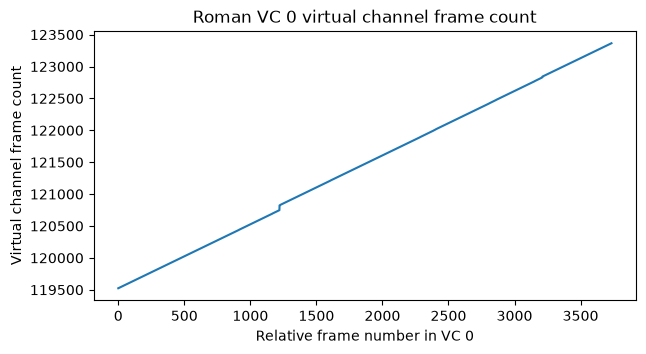

In [15]:
plt.plot(vcfc[vcid == 0])
plt.title('Roman VC 0 virtual channel frame count')
plt.xlabel('Relative frame number in VC 0')
plt.ylabel('Virtual channel frame count');

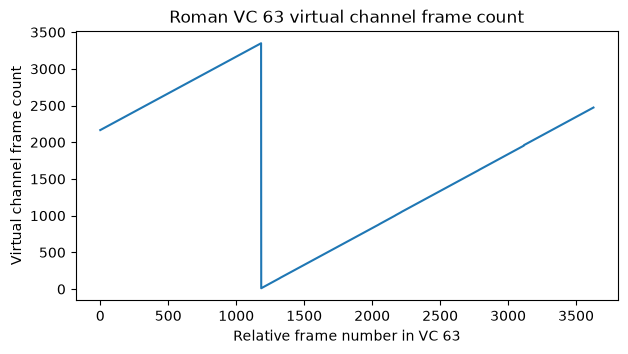

In [16]:
plt.plot(vcfc[vcid == 63])
plt.title('Roman VC 63 virtual channel frame count')
plt.xlabel('Relative frame number in VC 63')
plt.ylabel('Virtual channel frame count');

In [17]:
vcfc_63_unwrap = np.copy(vcfc[vcid == 63])
reset_point = np.where(np.diff(vcfc_63_unwrap) < 0)[0][0]
vcfc_63_unwrap[reset_point+1:] += vcfc_63_unwrap[reset_point] - vcfc_63_unwrap[reset_point+1]
vcfc[vcid == 63][reset_point-4:reset_point+4]

array([3345, 3346, 3347, 3348, 3349,   11,   12,   13])

In [18]:
# recover relative master channel frame count from virtual channel frame counts
mcfc = np.zeros_like(vcid)
for j in range(1, mcfc.size):
    if vcid[j] not in [0, 63]:
        delta = 1
    else:
        fc_prev = vcfc[:j][vcid[:j] == vcid[j]]
        if fc_prev.size:
            fc_prev = fc_prev[-1]
            delta = vcfc[j] - fc_prev
            if delta < 0:
                print(f'negative delta = {delta} at j = {j}')
                delta = 1
        else:
            delta = 1
    mcfc[j] = mcfc[j - 1] + delta

negative delta = -3338 at j = 2413


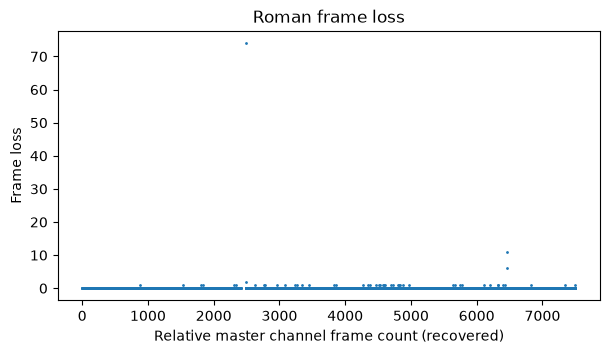

In [19]:
sel = (vcid == 0) | (vcid == 63)
plt.plot(mcfc[sel][1:], np.diff(mcfc[sel]) - 1, '.', markersize=2)
plt.title('Roman frame loss')
plt.xlabel('Relative master channel frame count (recovered)')
plt.ylabel('Frame loss');

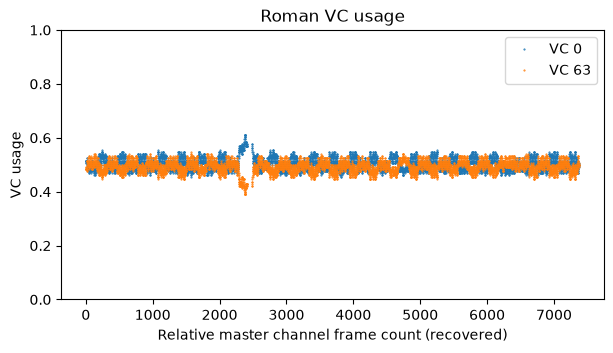

In [20]:
Navg = 128
plt.plot(mcfc[:-(Navg-1)], np.convolve(vcid == 0, np.ones(Navg) / Navg, mode='valid'), '.', label='VC 0', markersize=1)
plt.plot(mcfc[:-(Navg-1)], np.convolve(vcid == 63, np.ones(Navg) / Navg, mode='valid'), '.', label='VC 63', markersize=1)
plt.ylim(0, 1)
plt.legend()
plt.title('Roman VC usage')
plt.xlabel('Relative master channel frame count (recovered)')
plt.ylabel('VC usage');

In [21]:
assert np.all(frames[vcid == 63, 6:] == frames[vcid == 63][0, 6:])
filler = frames[vcid == 63][0, 8:]
assert np.all(filler == np.arange(filler.size, dtype='uint8'))

In [22]:
# If the M_PDU Packet Zone contains only Idle Data, the First Header Pointer shall
# be set to ‘all ones minus one’.
[a.m_pdu_header for a in aos if a.primary_header.virtual_channel_id == 63][0]

Container(rsv_spare=0, first_header_pointer=2046)

In [23]:
clcw = [a.ocf for a in aos if a.primary_header.virtual_channel_id == 0]
clcw[:10]

[Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=True, no_bit_lock=True, lock_out=False, wait=False, retransmit=False, farm_b_counter=1, rsvd_spare2=0, report_value=78),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=True, no_bit_lock=True, lock_out=False, wait=False, retransmit=False, farm_b_counter=1, rsvd_spare2=0, report_value=78),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=True, no_bit_lock=True, lock_out=False, wait=False, retransmit=False, farm_b_counter=1, rsvd_spare2=0, report_value=78),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=True, no_bit_lock=True, lock_

In [24]:
collections.Counter([(c.control_word_type, c.clcw_version_number, c.status_field, c.cop_in_effect,
                      c.virtual_channel_identification, c.rsvd_spare, c.no_rf_avail, c.no_bit_lock, c.lock_out,
                      c.wait, c.retransmit, c.farm_b_counter, c.rsvd_spare2)
                     for c in clcw])

Counter({(False, 0, 0, 1, 0, 0, True, True, False, False, False, 1, 0): 3735})

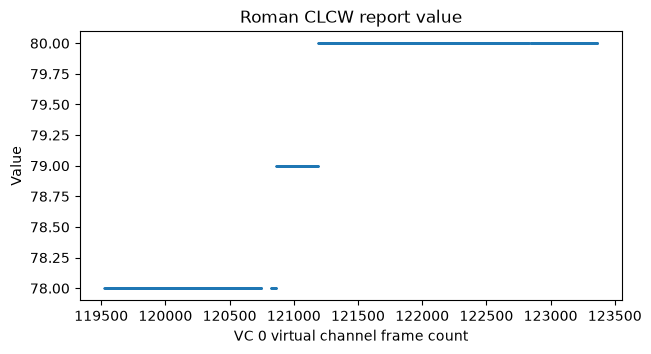

In [25]:
plt.plot(vcfc[vcid == 0], [c.report_value for c in clcw], '.', markersize=1)
plt.title('Roman CLCW report value')
plt.xlabel('VC 0 virtual channel frame count')
plt.ylabel('Value');

In [26]:
report_jumps = np.where(np.diff([c.report_value for c in clcw]))[0]
for report_jump in report_jumps:
    packets_jump = list(ccsds.extract_space_packets(
        [[a for a in aos if a.primary_header.virtual_channel_id == 0][report_jump]],
        39, 0))
    t_jump = ((struct.unpack('>Q', packets_jump[0][ccsds.SpacePacketPrimaryHeader.sizeof():][:8])[0] / 2**32 * 1e9) * np.timedelta64(1, 'ns')
     + np.datetime64('1958-01-01T00:00:00'))
    delta_jump = (t_jump - np.datetime64('2026-08-31T05:33:03')) / np.timedelta64(1, 's')
    print(t_jump, delta_jump)

2026-08-31T07:02:39.496320768 5376.496320768
2026-08-31T07:20:15.920888064 6432.920888064


## VC 0

Virtual channel 0 contains CCSDS Space Packets using M_PDU. All the space packets have an 8-byte secondary header that contains a timestamp as number of `2**(-32)` second units since the CCSDS epoch 1958-01-01T00:00:00 TAI. There are no idle space packets. All the packets in each APID have the same size.

In [27]:
packets = list(ccsds.extract_space_packets(aos, 39, 0))

/home/daniel/contracting/Roman/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 39 VC 0] Broken stream. Last frame count 119968, current frame count 119970
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/Roman/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 39 VC 0] Broken stream. Last frame count 120437, current frame count 120439
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/Roman/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 39 VC 0] Broken stream. Last frame count 120457, current frame count 120459
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame

In [28]:
headers = [ccsds.SpacePacketPrimaryHeader.parse(p) for p in packets]

In [29]:
headers[:10]

[Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=485, sequence_flags=3, packet_sequence_count_or_name=11488, data_length=521),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=161, sequence_flags=3, packet_sequence_count_or_name=11488, data_length=30),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=200, sequence_flags=3, packet_sequence_count_or_name=13184, data_length=33),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=103, sequence_flags=3, packet_sequence_count_or_name=13184, data_length=85),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=133, sequence_flags=3, packet_sequence_count_or_name=13184, data_length=169),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=94, sequence_flags=3, packet_sequence_count_or_name=13184, data_length=161),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=493,

In [30]:
apids = collections.Counter([p.APID for p in headers])
apids

Counter({131: 3090,
         94: 3087,
         133: 3086,
         141: 1546,
         188: 1545,
         118: 775,
         138: 773,
         464: 773,
         160: 773,
         161: 772,
         465: 772,
         103: 771,
         149: 771,
         150: 770,
         44: 411,
         490: 388,
         498: 388,
         20: 388,
         469: 388,
         219: 387,
         220: 387,
         231: 387,
         232: 387,
         243: 387,
         244: 387,
         178: 387,
         179: 387,
         19: 387,
         477: 387,
         485: 386,
         200: 386,
         493: 386,
         189: 386,
         16: 386,
         32: 385,
         22: 385,
         206: 385,
         24: 385,
         3: 384,
         2: 384,
         38: 384,
         36: 383,
         4: 382,
         25: 381,
         317: 205,
         263: 194,
         180: 194,
         310: 194,
         158: 194,
         43: 194,
         139: 194,
         271: 193,
         296: 193,
      

In [31]:
{apid: collections.Counter([p.data_length for p in headers if p.APID == apid])
 for apid in apids}

{485: Counter({521: 386}),
 161: Counter({30: 772}),
 200: Counter({33: 386}),
 103: Counter({85: 771}),
 133: Counter({169: 3086}),
 94: Counter({161: 3087}),
 493: Counter({521: 386}),
 141: Counter({21: 1546}),
 138: Counter({337: 773}),
 490: Counter({517: 388}),
 118: Counter({209: 775}),
 498: Counter({517: 388}),
 20: Counter({61: 388}),
 263: Counter({609: 194}),
 271: Counter({425: 193}),
 44: Counter({57: 411}),
 188: Counter({81: 1545}),
 131: Counter({49: 3090}),
 296: Counter({127: 193}),
 219: Counter({51: 387}),
 220: Counter({55: 387}),
 231: Counter({51: 387}),
 232: Counter({55: 387}),
 56: Counter({1609: 25}),
 57: Counter({4873: 24}),
 309: Counter({201: 193}),
 149: Counter({30: 771}),
 150: Counter({30: 770}),
 465: Counter({41: 772}),
 464: Counter({73: 773}),
 160: Counter({30: 773}),
 189: Counter({29: 386}),
 173: Counter({37: 97}),
 175: Counter({51: 97}),
 180: Counter({77: 194}),
 310: Counter({521: 194}),
 243: Counter({51: 387}),
 244: Counter({55: 387}),

In [32]:
def payloads_by_apid(apid):
    return [p[ccsds.SpacePacketPrimaryHeader.sizeof() + 8:] for (h, p) in zip(headers, packets)
            if h.APID == apid]

def array_by_apid(apid):
    return np.array([np.frombuffer(p, 'uint8') for p in payloads_by_apid(apid)])

def plot_apid(apid, *, vmax=255, byte_sel=None):
    plt.figure(figsize=(10, 4))
    a = array_by_apid(apid)
    if byte_sel is not None:
        a = a[:, byte_sel]
    plt.imshow(a, aspect='auto', interpolation='None', vmin=0, vmax=vmax)
    plt.title(f'Roman APID {apid}')
    plt.ylabel('Packet number')
    plt.xlabel('Payload byte number')

In [33]:
secondary_headers = np.array([np.frombuffer(p[ccsds.SpacePacketPrimaryHeader.sizeof():][:8], 'uint8') for p in packets])
packet_timestamps = ((secondary_headers.view('uint64').byteswap().ravel() / 2**32 * 1e9) * np.timedelta64(1, 'ns')
                     + np.datetime64('1958-01-01T00:00:00'))
apid_timestamps = {apid: packet_timestamps[np.array([h.APID for h in headers]) == apid] for apid in apids}

In [34]:
packet_timestamps[0]

np.datetime64('2026-08-31T05:33:03.855878912')

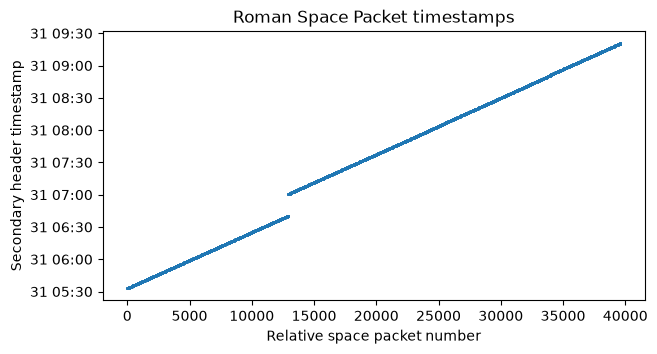

In [35]:
plt.plot(packet_timestamps, '.', markersize=1)
plt.title('Roman Space Packet timestamps')
plt.ylabel('Secondary header timestamp')
plt.xlabel('Relative space packet number');

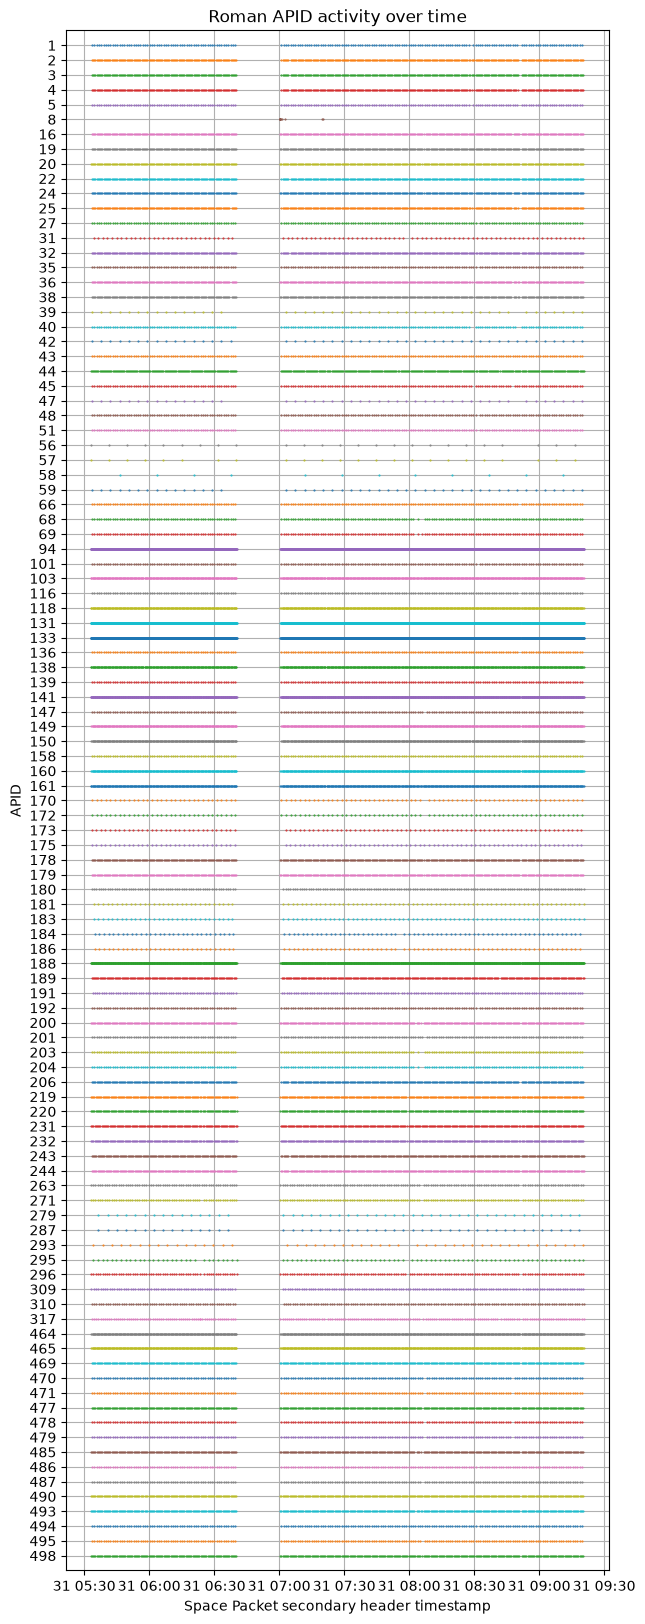

In [36]:
plt.figure(figsize=(7, 20))
for k, apid in enumerate(sorted(apids)):
    ts = apid_timestamps[apid]
    plt.plot(ts, len(ts) * [-k], '.', color=f'C{k}', markersize=1)
plt.yticks(-np.arange(len(apids)), [str(a) for a in sorted(apids)])
plt.ylim(-len(apids), 1)
plt.grid()
plt.ylabel('APID')
plt.xlabel('Space Packet secondary header timestamp')
plt.title('Roman APID activity over time');

In [37]:
def unwrap_packet_sequence_count(x):
    y = np.copy(x)
    for j in range(1, y.size):
        if y[j] < y[j - 1]:
            y[j:] += 16384
    return y

def apid_sequence_count(apid):
    return unwrap_packet_sequence_count([p.packet_sequence_count_or_name for p in headers if p.APID == apid])

def apid_sequence_count_jumps(apid):
    return np.diff(unwrap_packet_sequence_count([p.packet_sequence_count_or_name for p in headers if p.APID == apid]))

In [38]:
{apid: collections.Counter(apid_sequence_count_jumps(apid))
 for apid in apids}

{485: Counter({np.int64(32): 380, np.int64(64): 4, np.int64(1216): 1}),
 161: Counter({np.int64(16): 763, np.int64(32): 7, np.int64(1216): 1}),
 200: Counter({np.int64(128): 380, np.int64(256): 4, np.int64(4864): 1}),
 103: Counter({np.int64(64): 761, np.int64(128): 8, np.int64(4864): 1}),
 133: Counter({np.int64(16): 3070,
          np.int64(32): 8,
          np.int64(48): 3,
          np.int64(64): 1,
          np.int64(4832): 1,
          np.int64(80): 1,
          np.int64(128): 1}),
 94: Counter({np.int64(16): 3072,
          np.int64(32): 6,
          np.int64(48): 5,
          np.int64(4832): 1,
          np.int64(80): 1,
          np.int64(128): 1}),
 493: Counter({np.int64(32): 380, np.int64(64): 4, np.int64(1216): 1}),
 141: Counter({np.int64(32): 1535,
          np.int64(64): 7,
          np.int64(4832): 1,
          np.int64(96): 1,
          np.int64(128): 1}),
 138: Counter({np.int64(64): 765, np.int64(128): 6, np.int64(4864): 1}),
 490: Counter({np.int64(32): 384, np.int

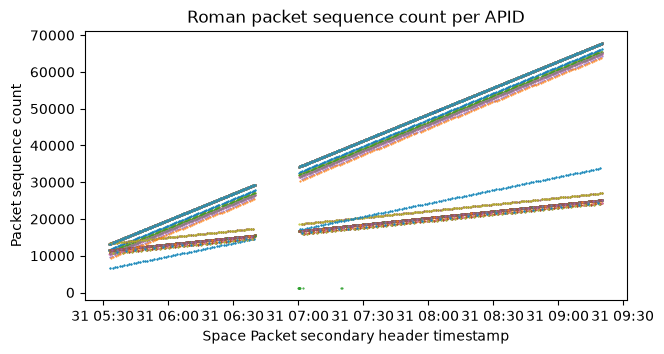

In [39]:
for apid in apids:
    plt.plot(apid_timestamps[apid], apid_sequence_count(apid), '.', markersize=1)
plt.ylabel('Packet sequence count')
plt.xlabel('Space Packet secondary header timestamp')
plt.title('Roman packet sequence count per APID');

In [40]:
packets_per_sec = {apid: float(np.average(apid_sequence_count_jumps(apid) /
                                         (np.diff(apid_timestamps[apid]) / np.timedelta64(1, 's'))))
 for apid in apids}
packets_per_sec

{485: 1.0000000009230576,
 161: 1.0000000051702704,
 200: 4.000000003526,
 103: 3.9999999987638137,
 133: 4.000000003234054,
 94: 3.999999989206549,
 493: 1.0000000010788999,
 141: 4.000000007509648,
 138: 4.000000008189303,
 490: 1.0000000011516623,
 118: 4.000000003412129,
 498: 1.0000000010189243,
 20: 1.0000000008415821,
 263: 1.0000000010990007,
 271: 1.0000000013284092,
 44: 0.9999999969899643,
 188: 4.00000000455088,
 131: 0.9999999987048327,
 296: 1.0000000008092222,
 219: 4.000000002604949,
 220: 4.000000004221522,
 231: 4.000000000621858,
 232: 4.0000000023104185,
 56: 1.0000000023329856,
 57: 1.000000001637982,
 309: 1.0000000004692573,
 149: 1.0000000113985479,
 150: 1.0000000003202405,
 465: 1.0000000008087508,
 464: 1.0000000011921282,
 160: 1.000000009540976,
 189: 1.0000000008862542,
 173: 1.0000000000000053,
 175: 0.9999999999242478,
 180: 4.000000002009419,
 310: 1.0000000007619156,
 243: 4.000000002326665,
 244: 4.000000004748863,
 317: 1.0000000055972795,
 27: 1.000

/tmp/ipykernel_71067/4071585476.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 4))


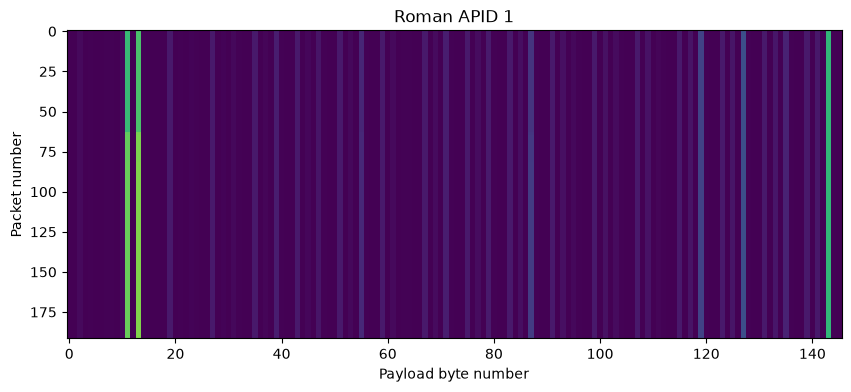

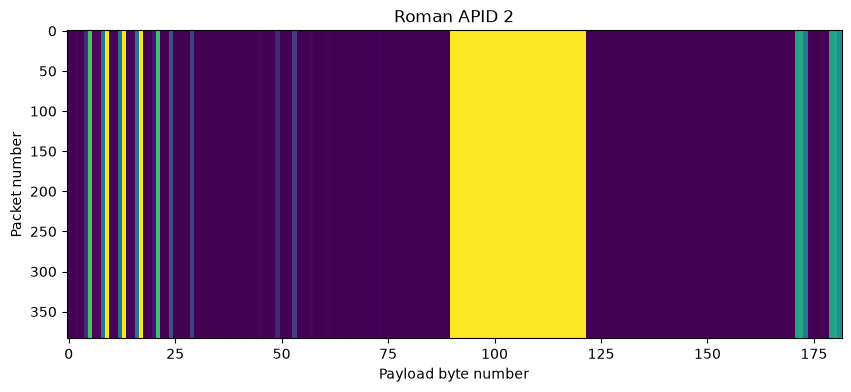

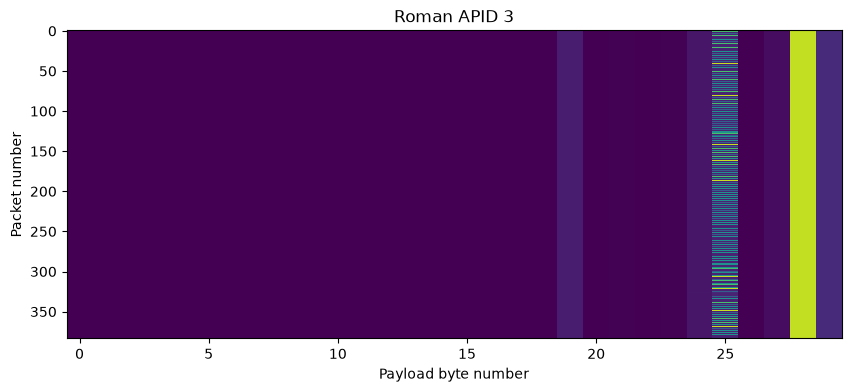

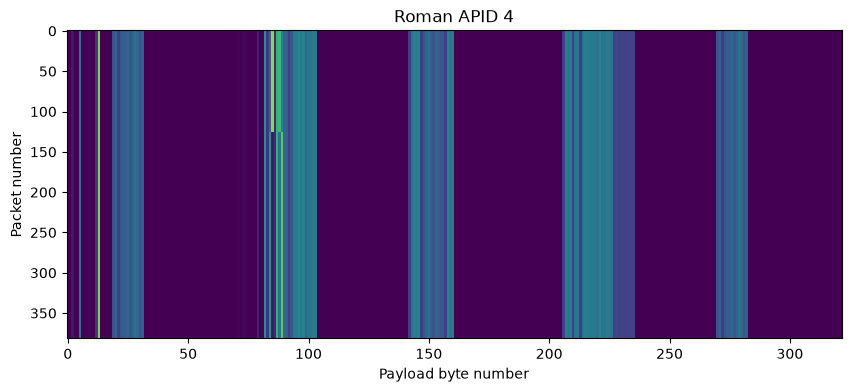

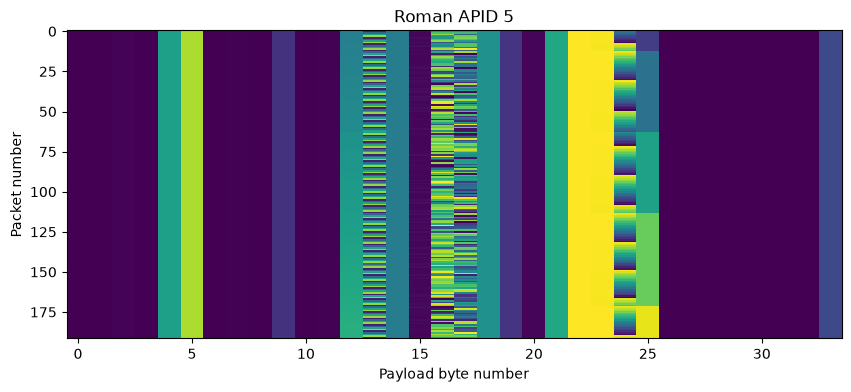

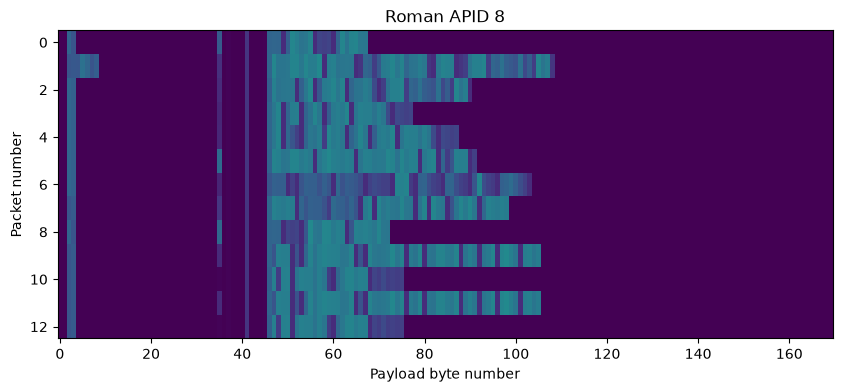

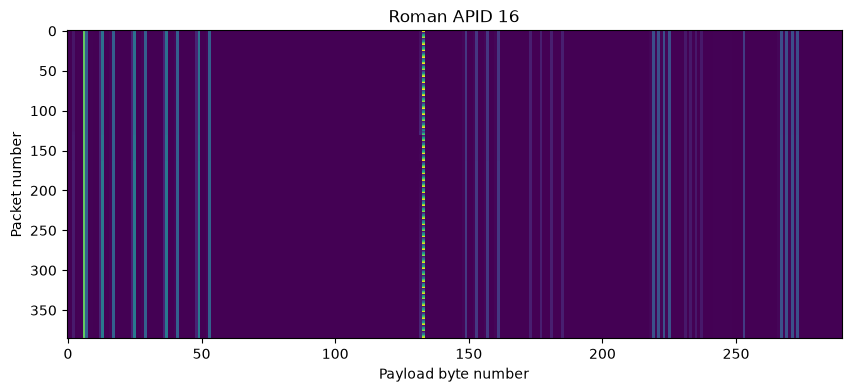

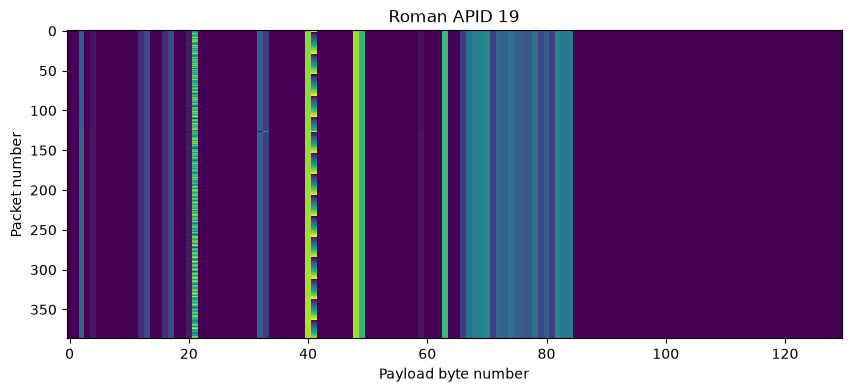

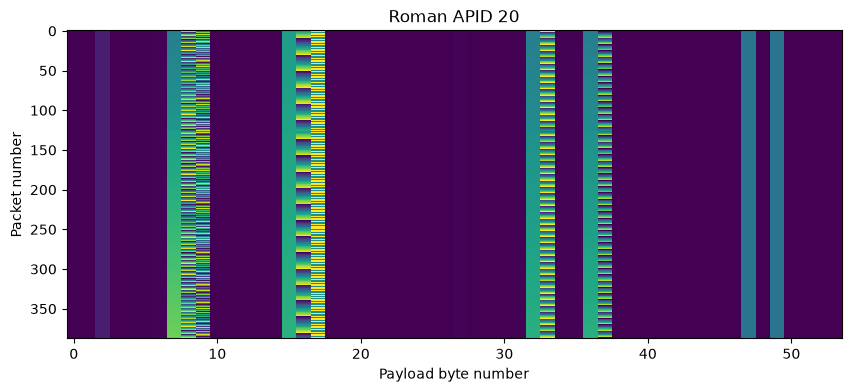

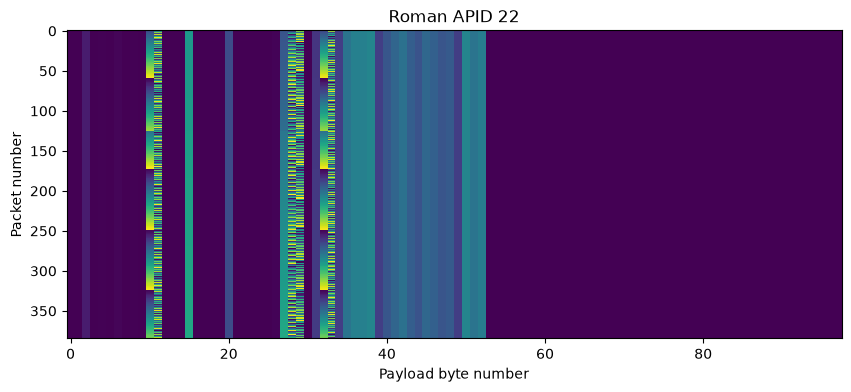

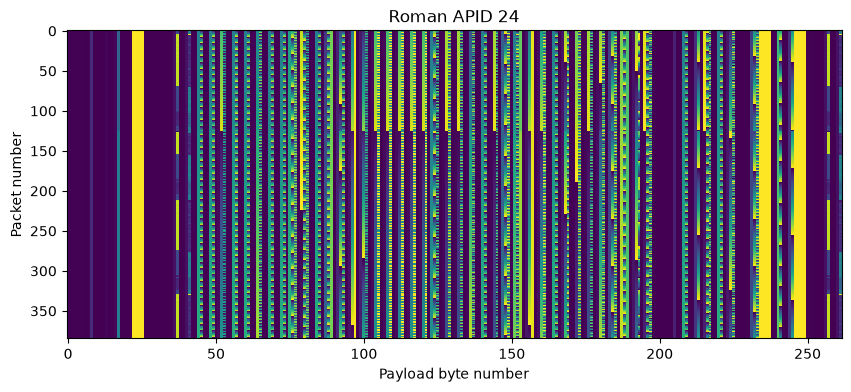

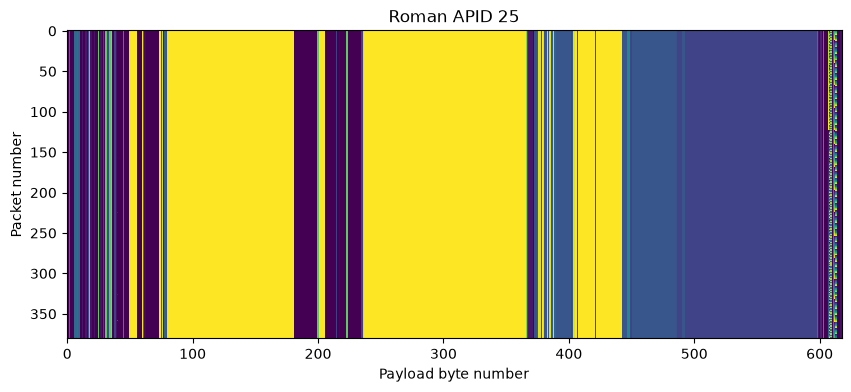

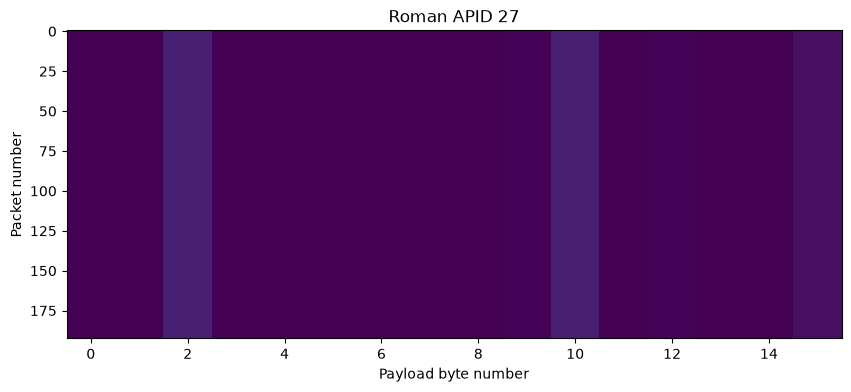

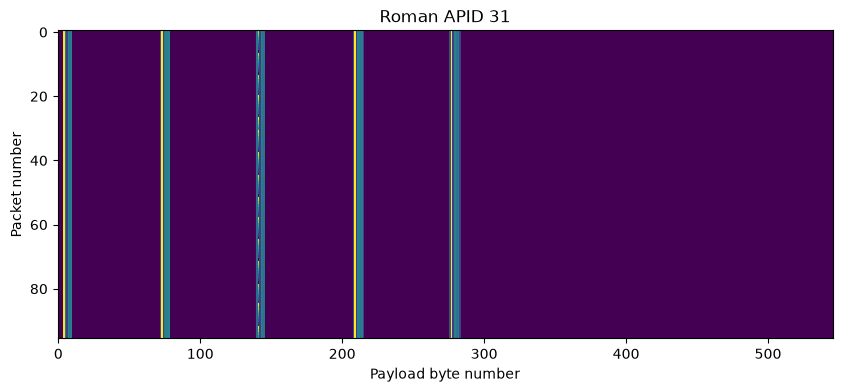

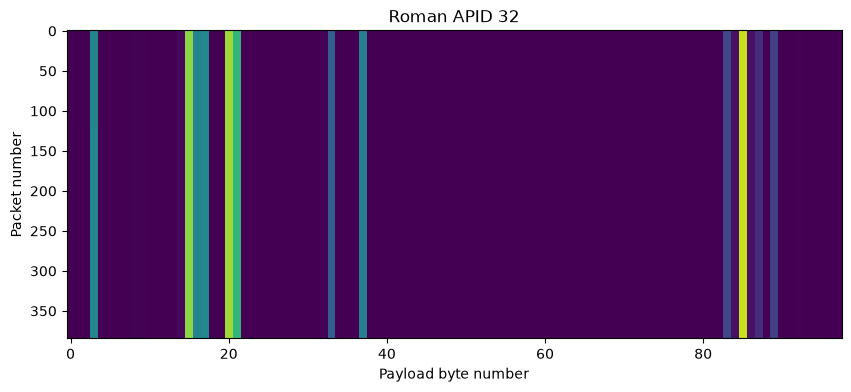

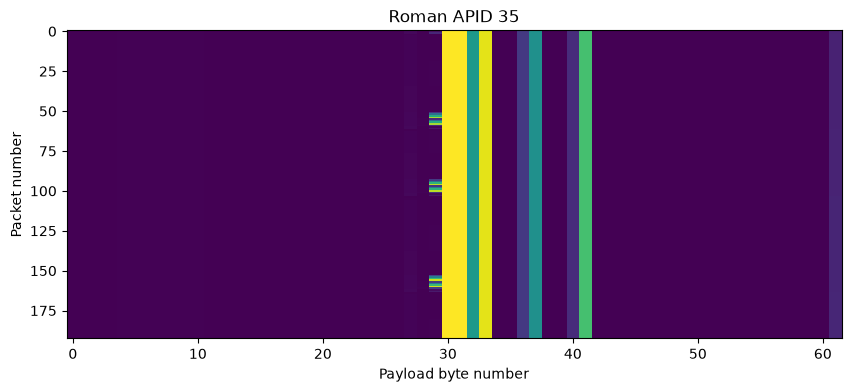

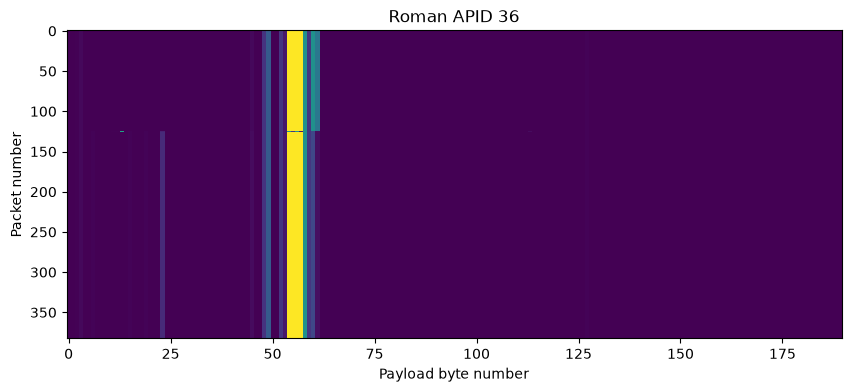

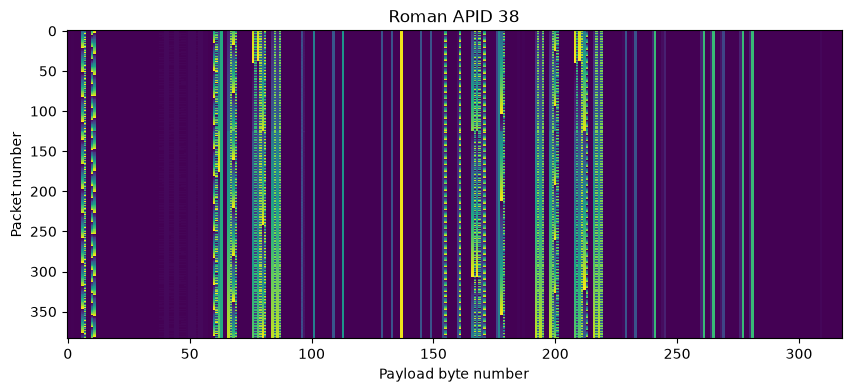

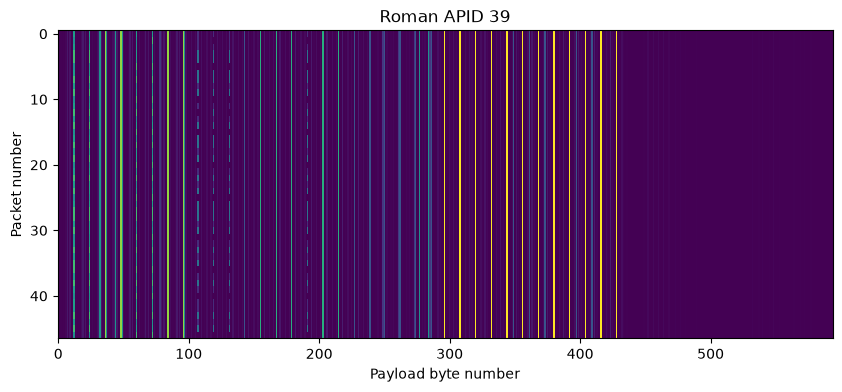

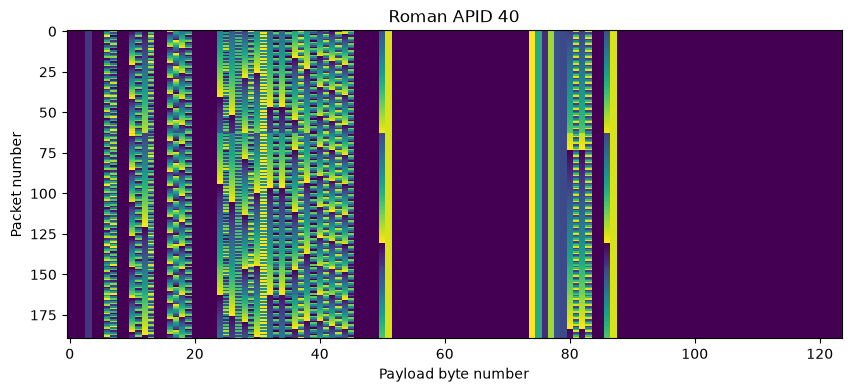

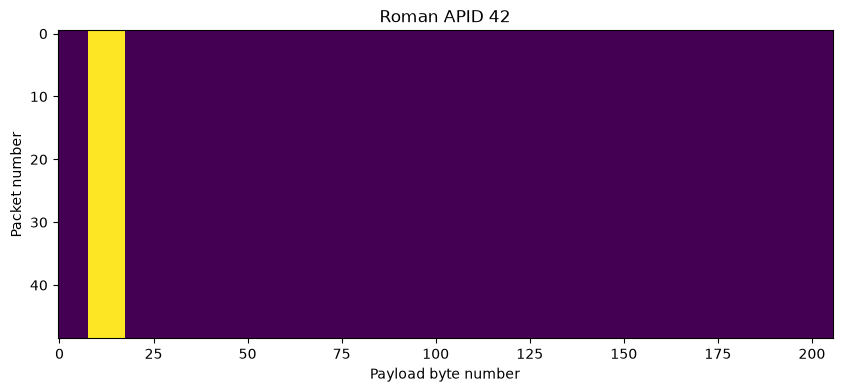

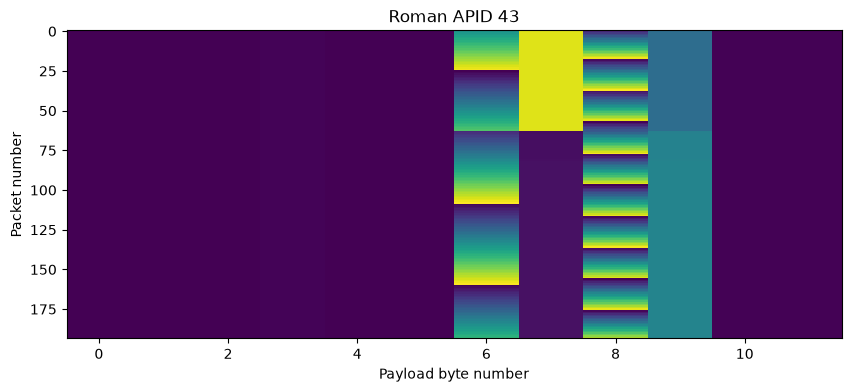

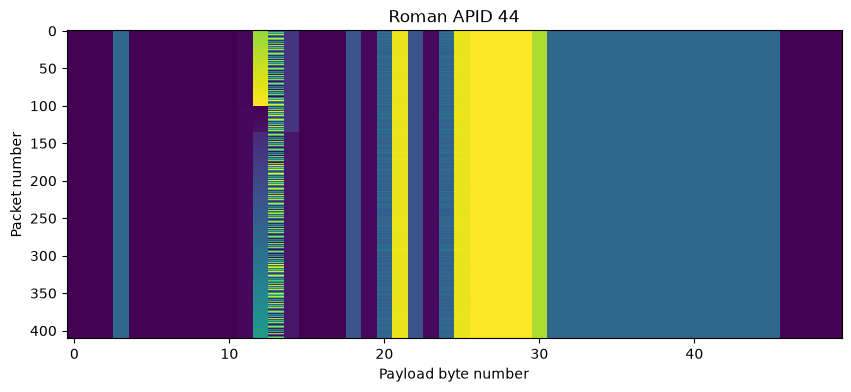

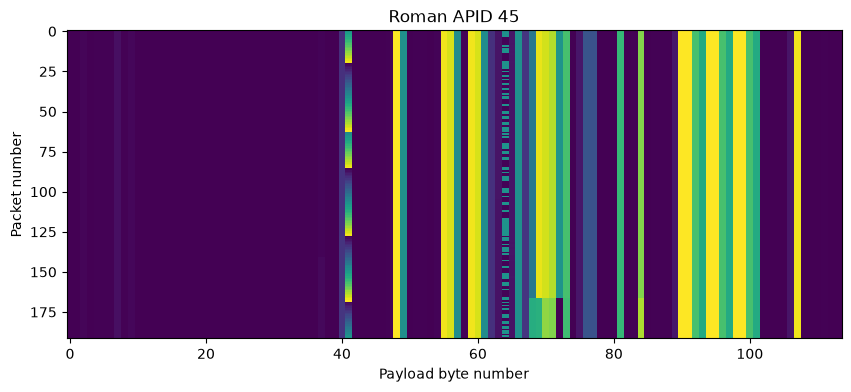

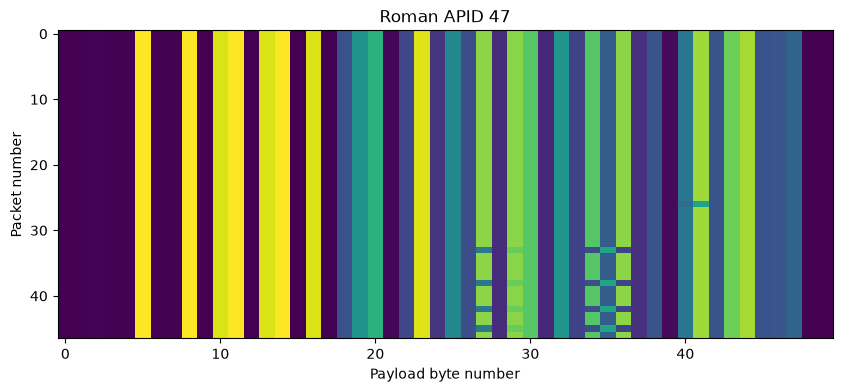

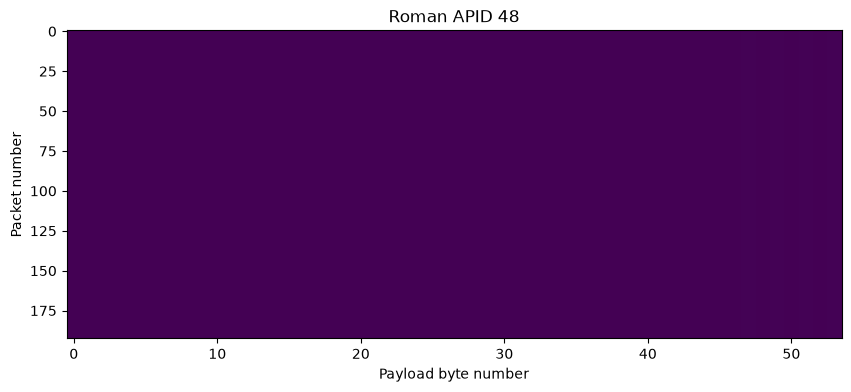

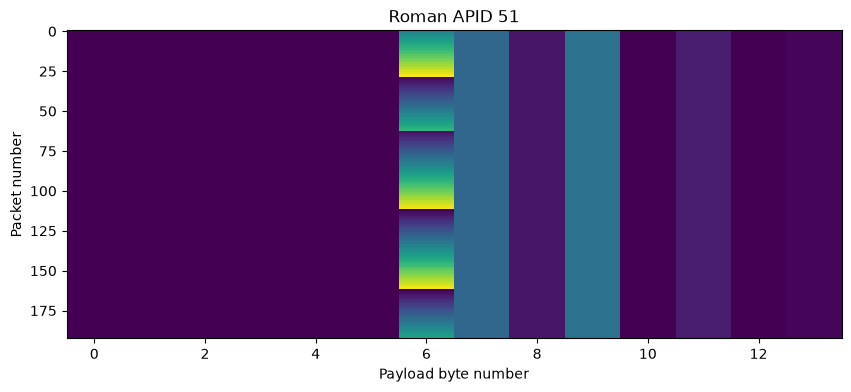

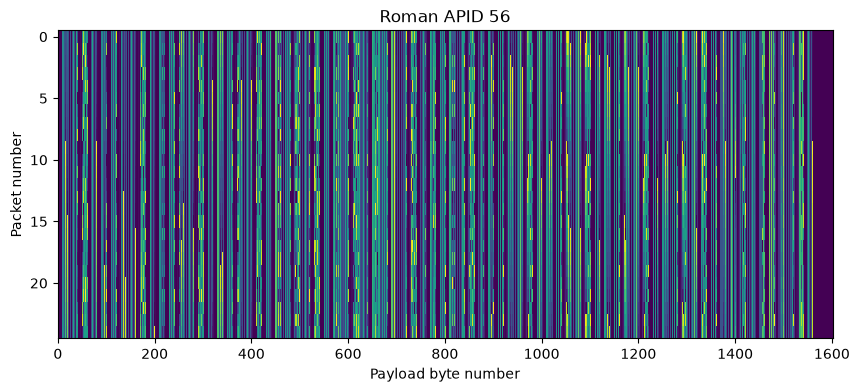

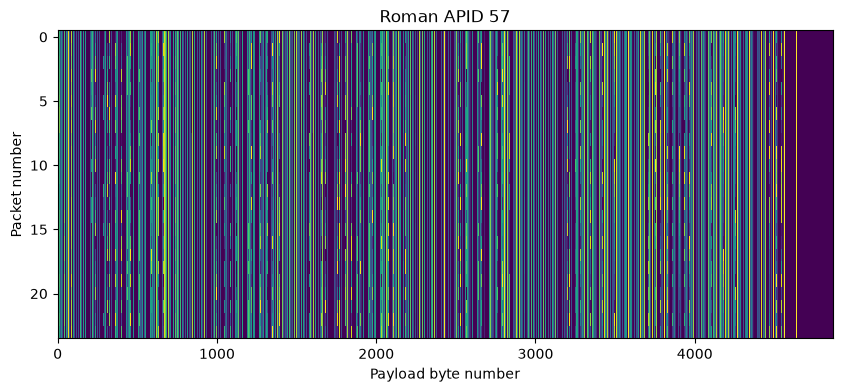

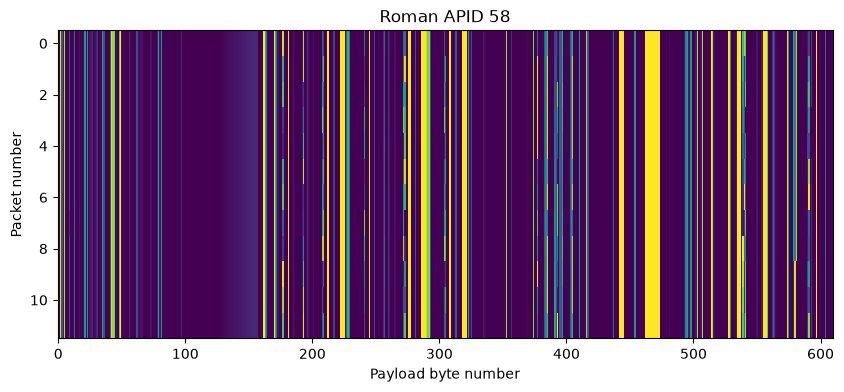

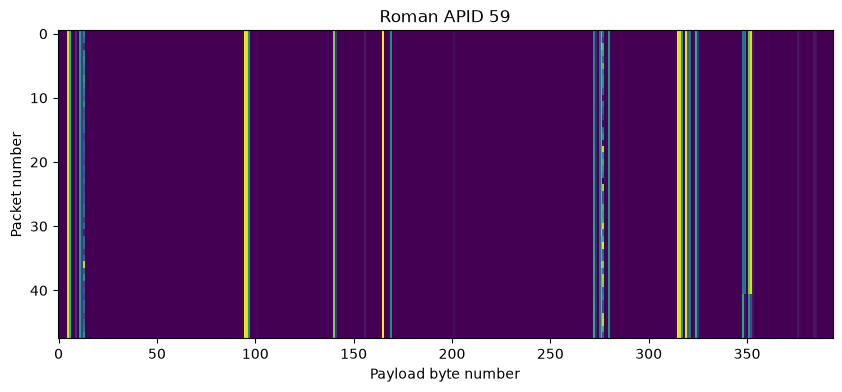

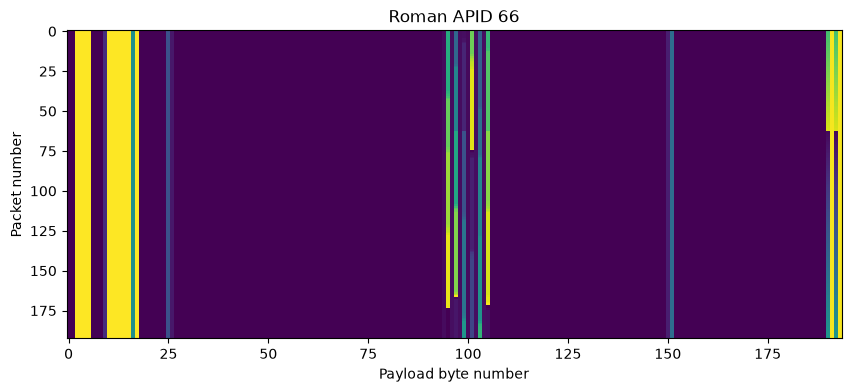

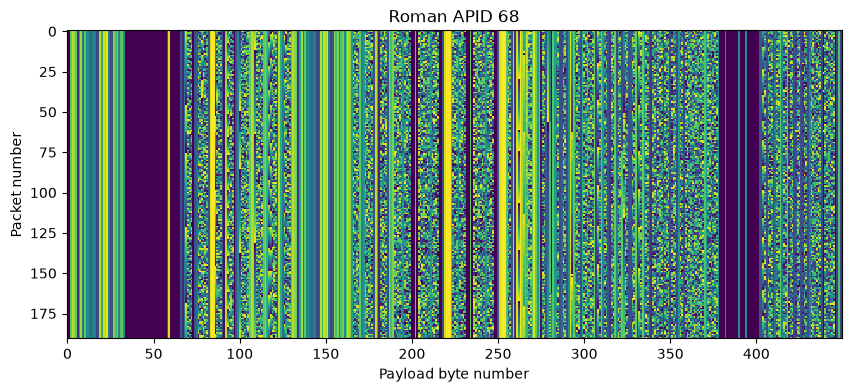

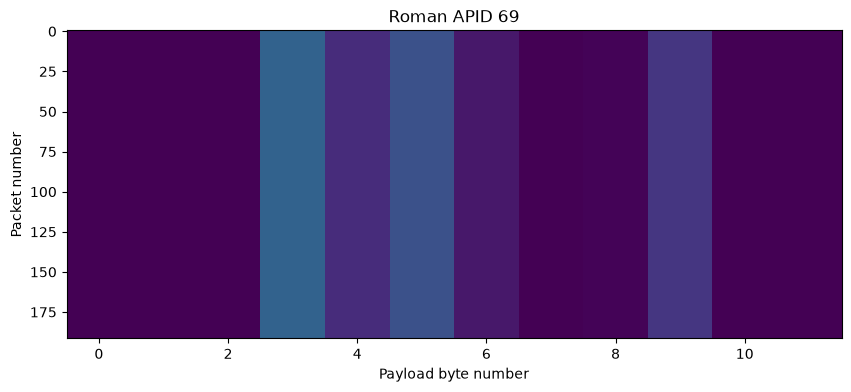

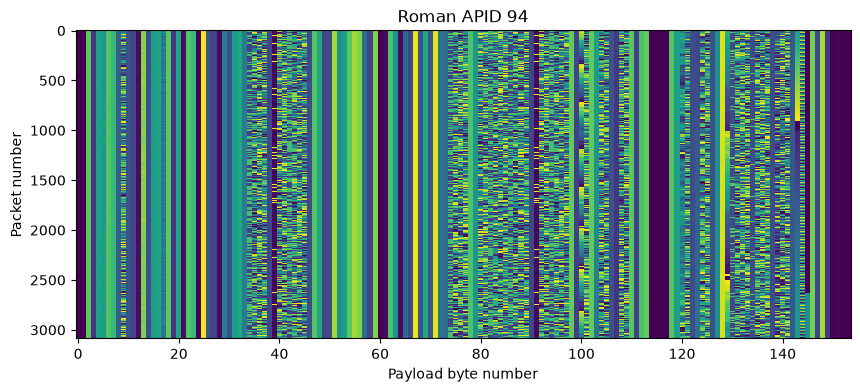

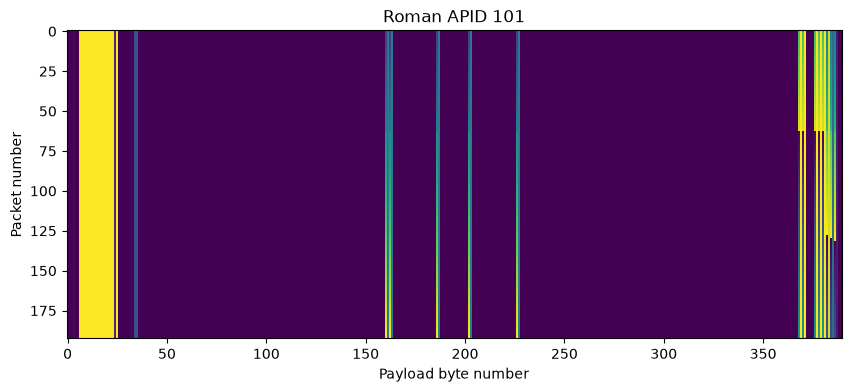

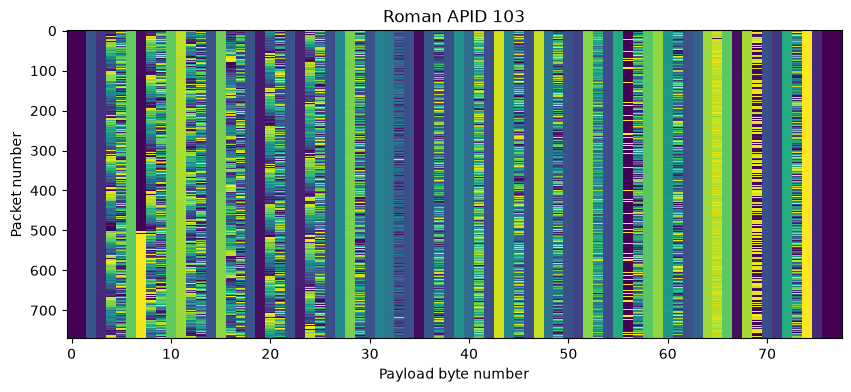

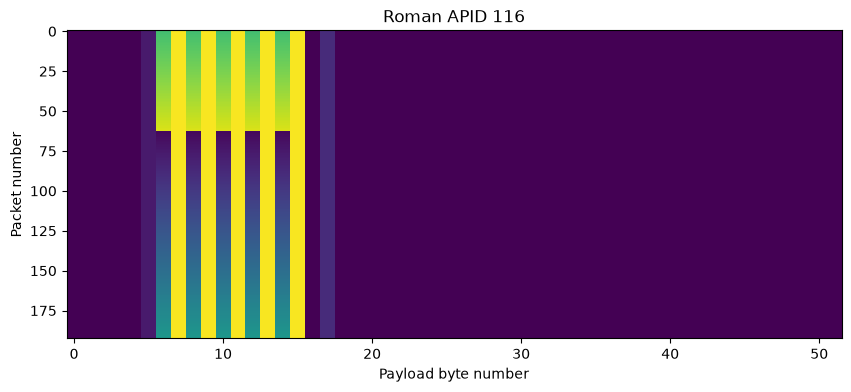

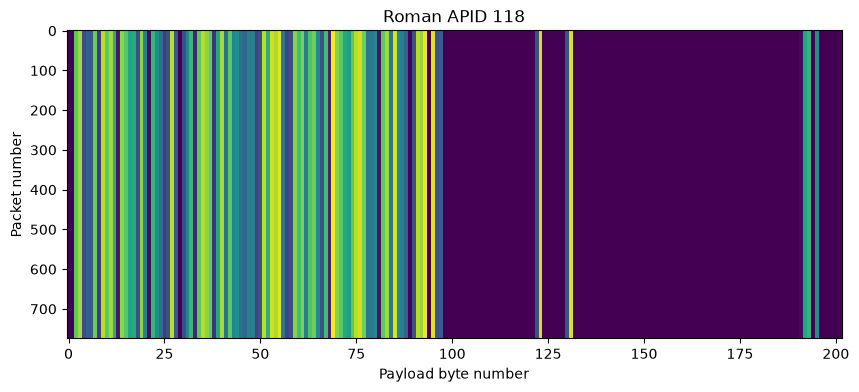

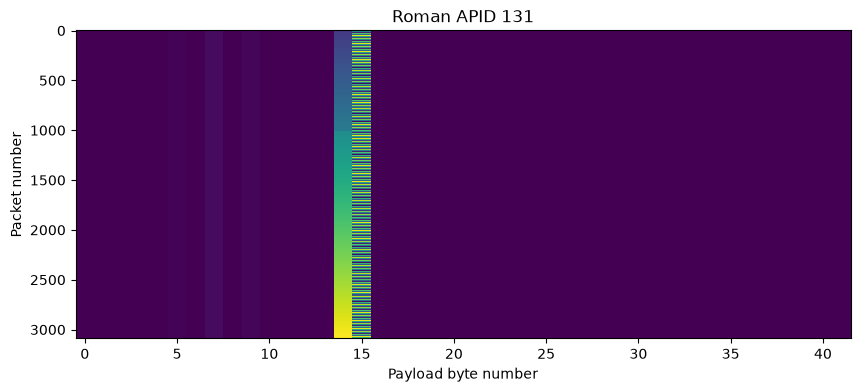

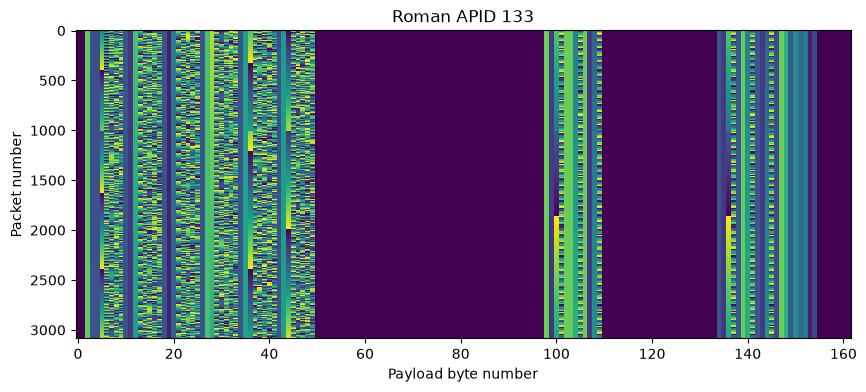

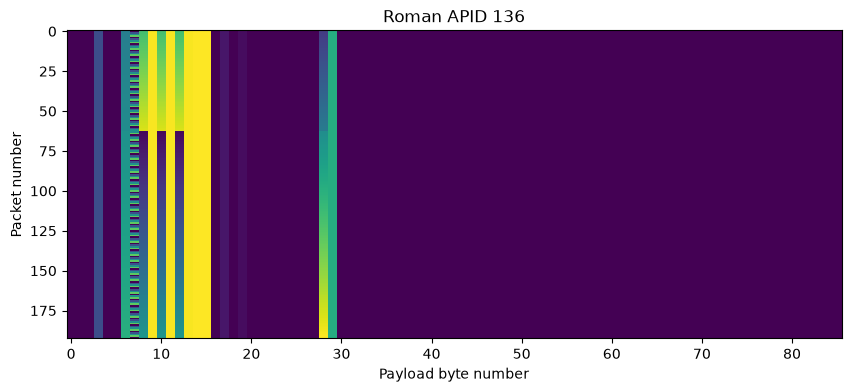

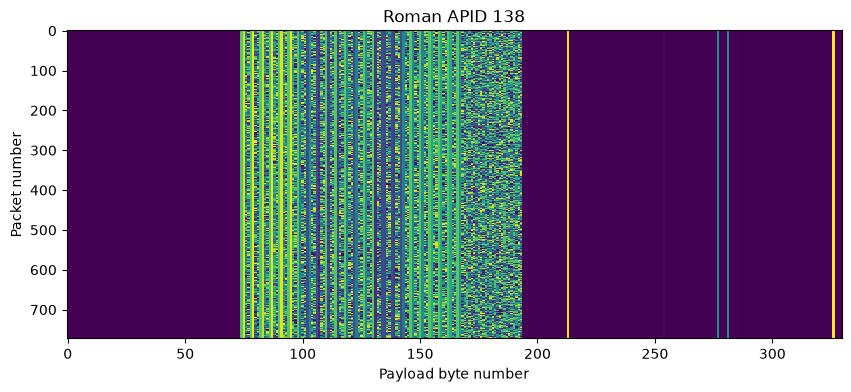

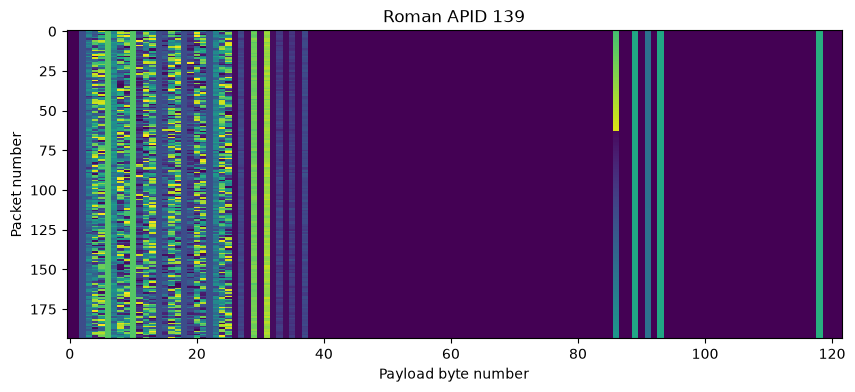

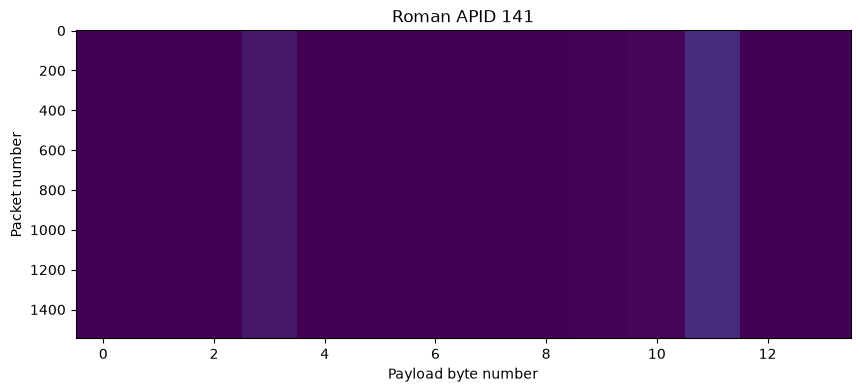

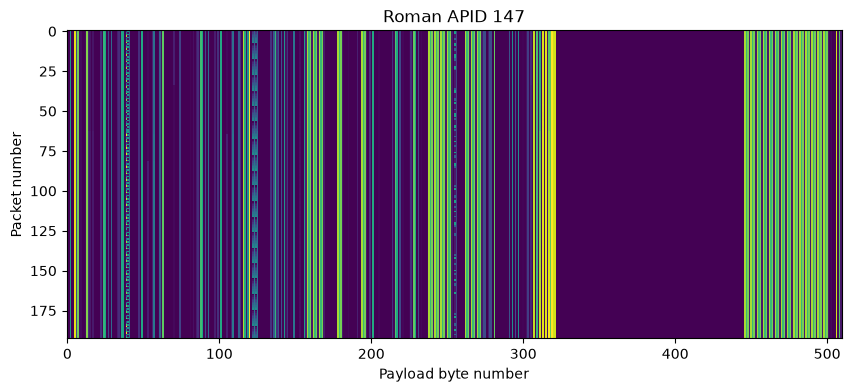

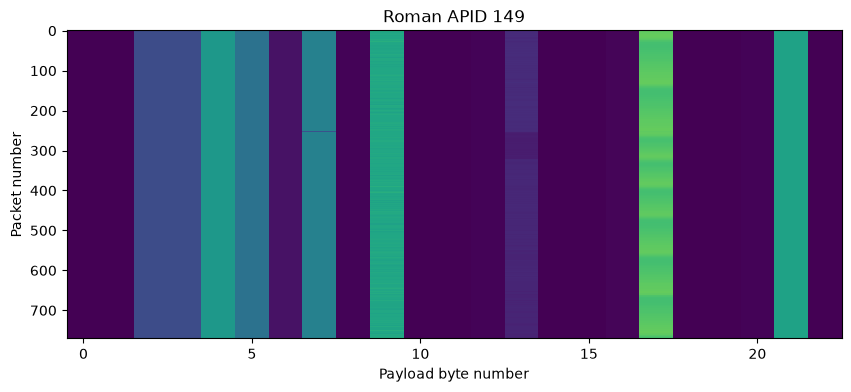

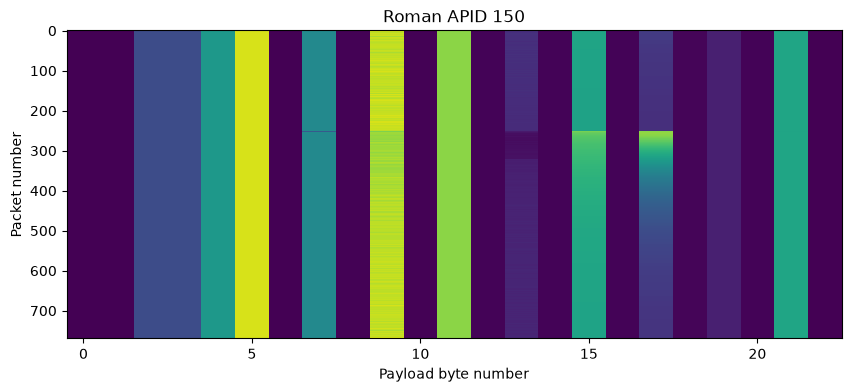

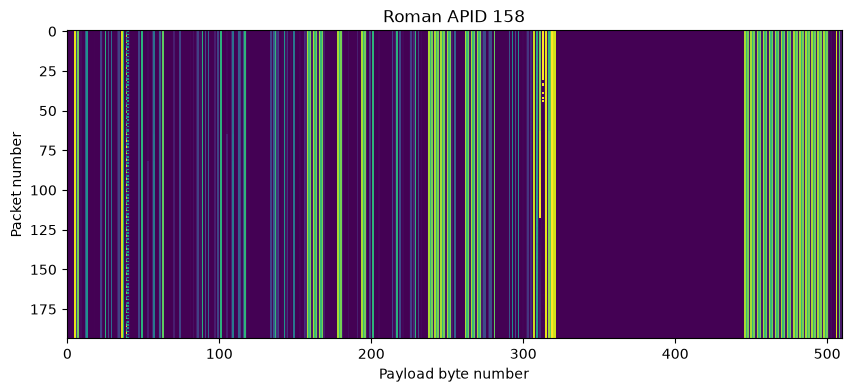

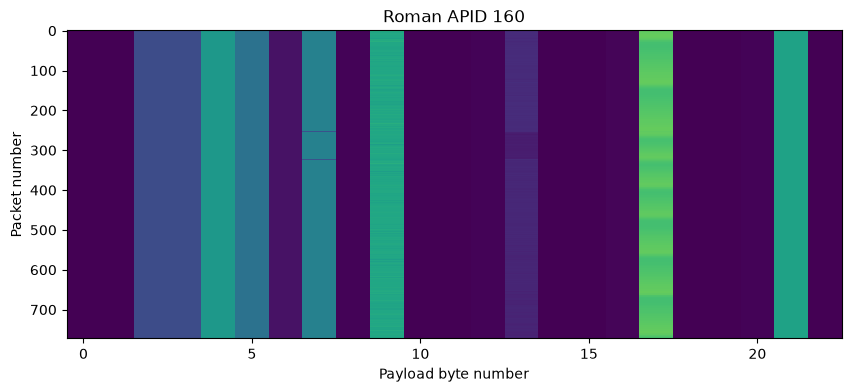

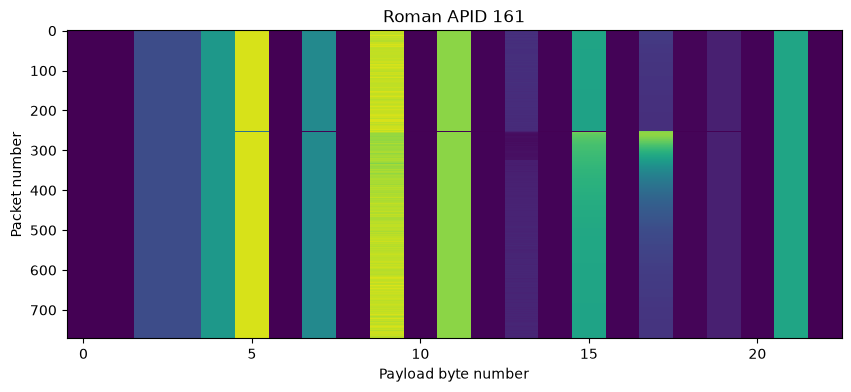

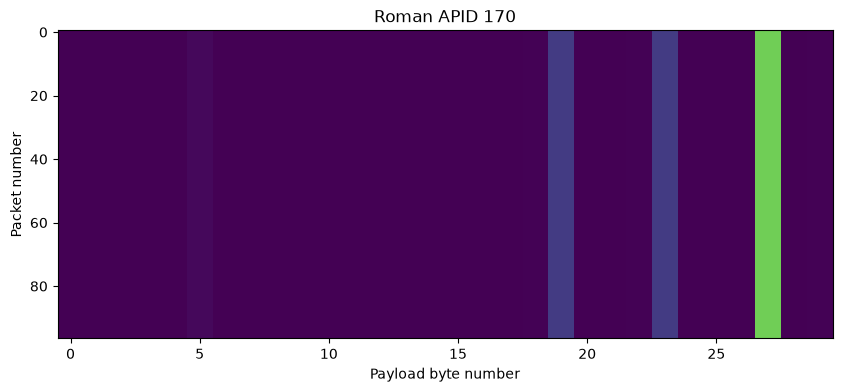

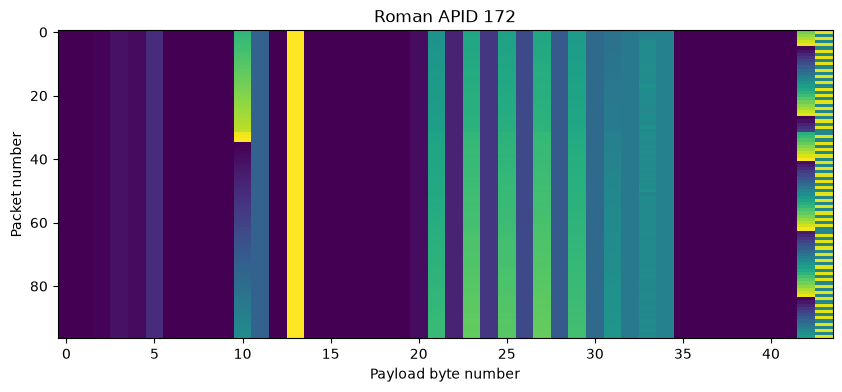

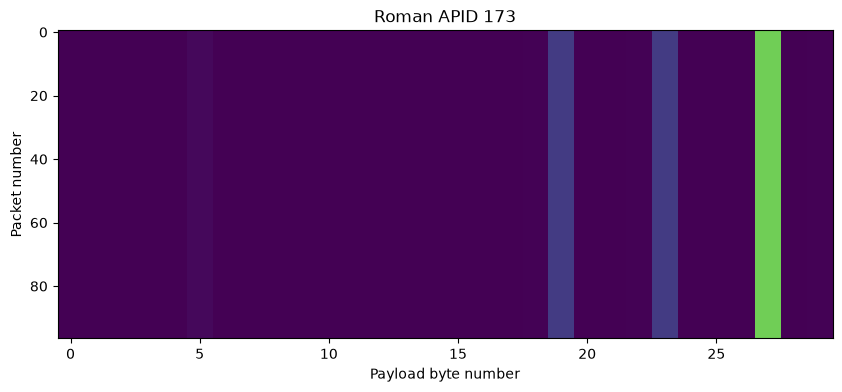

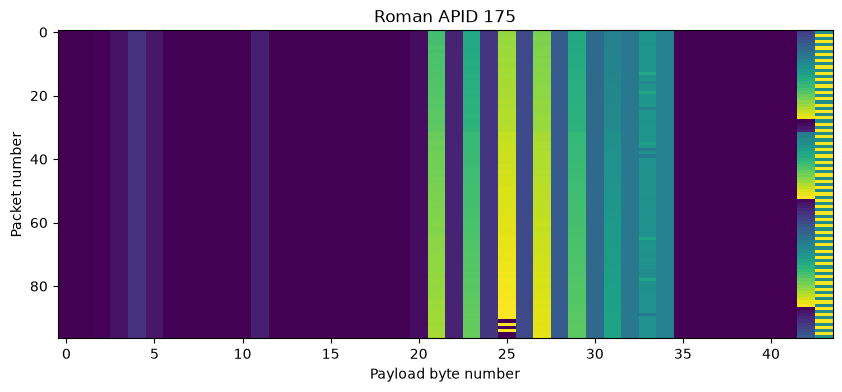

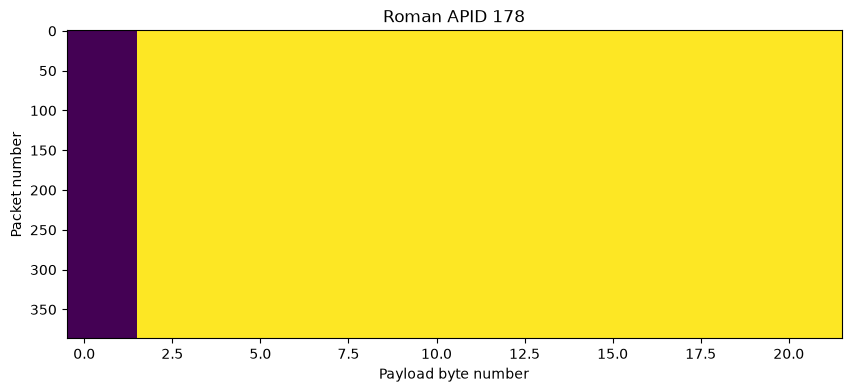

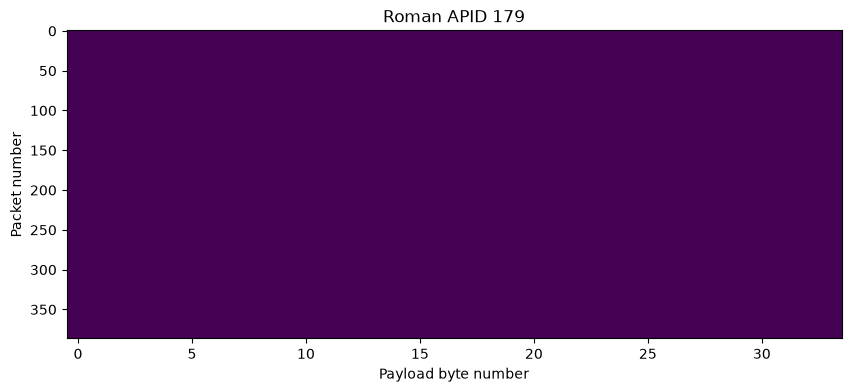

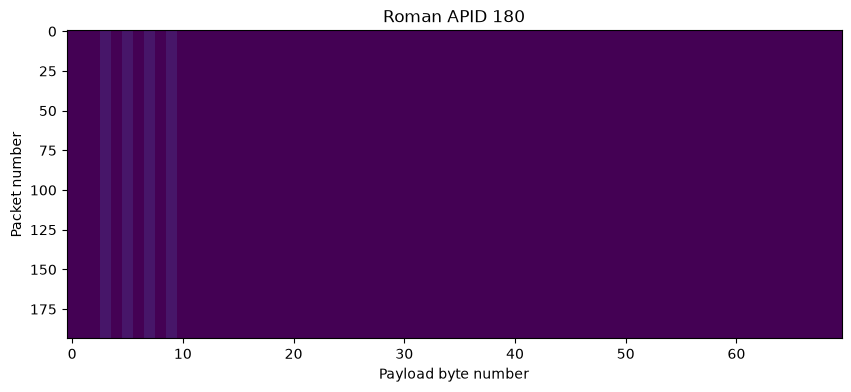

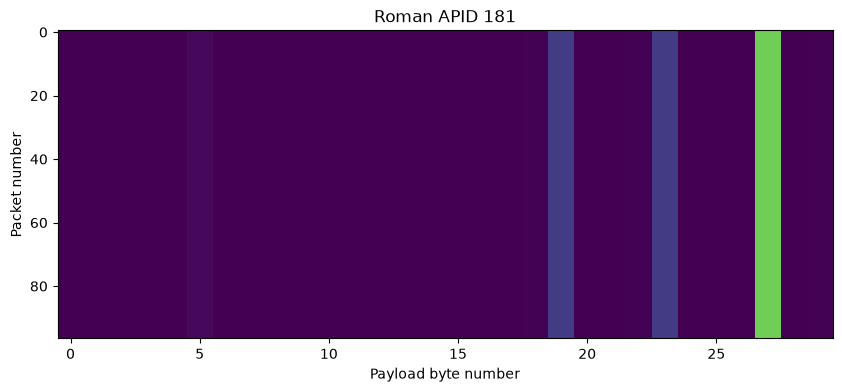

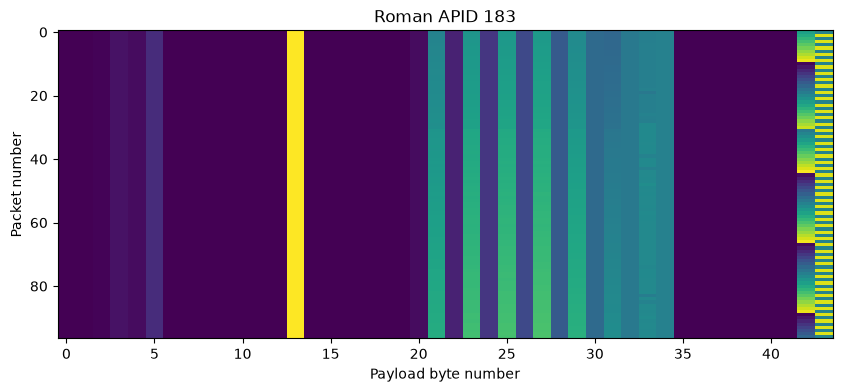

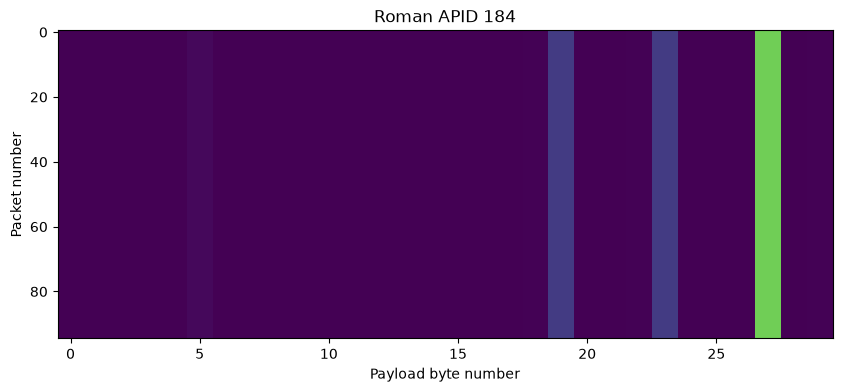

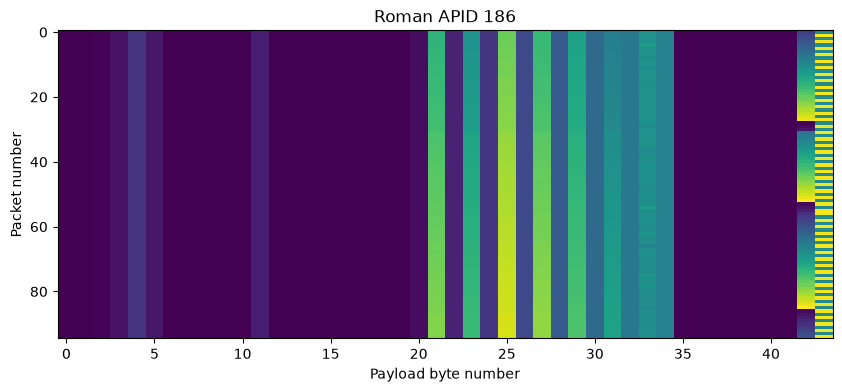

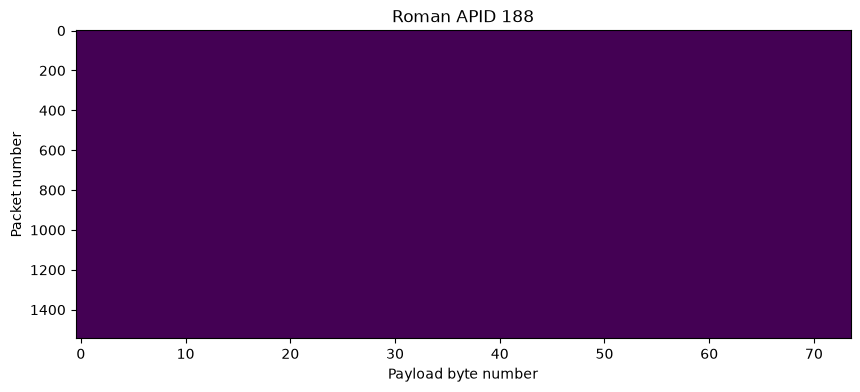

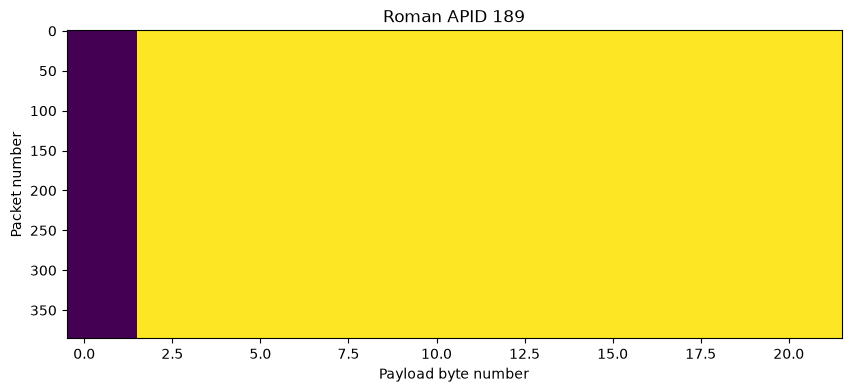

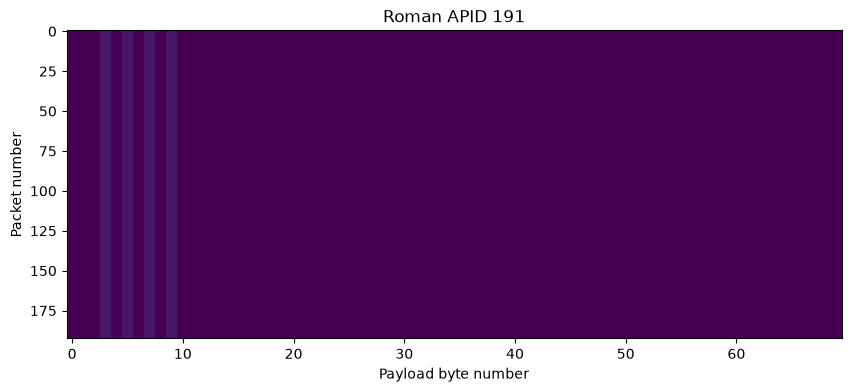

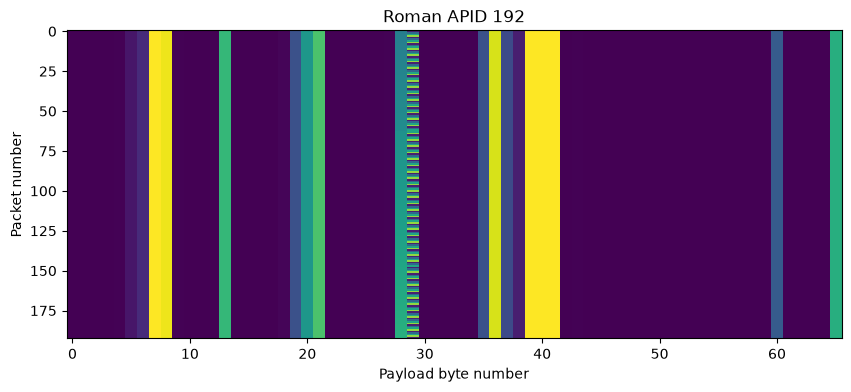

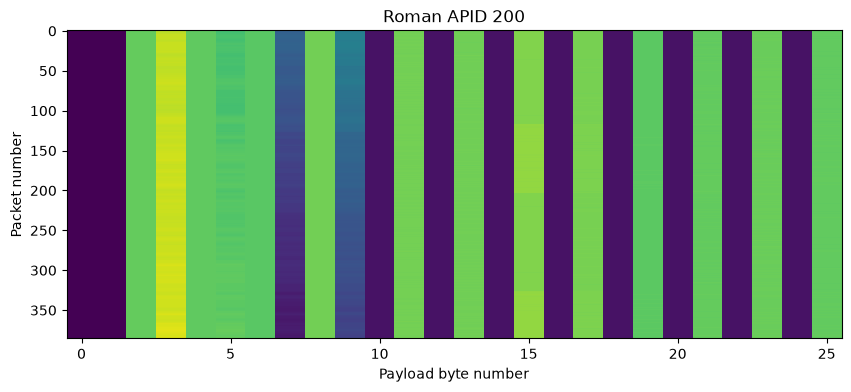

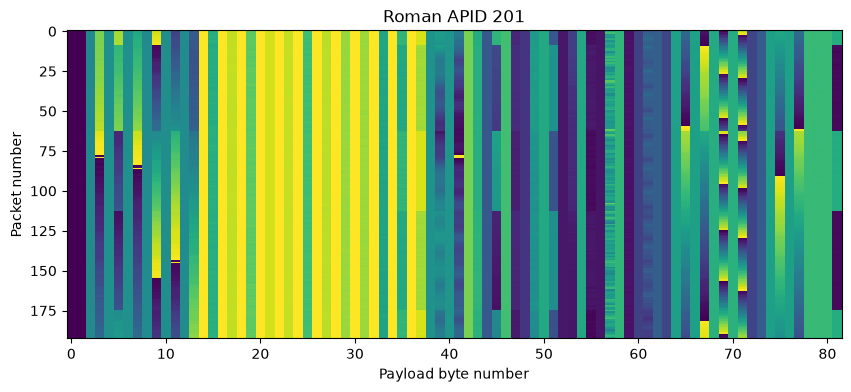

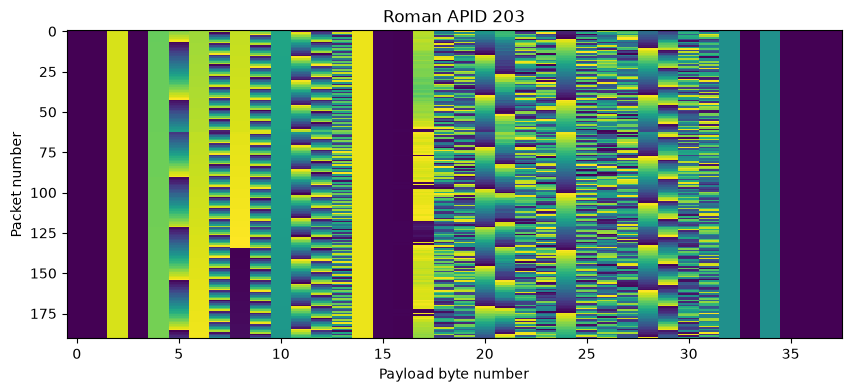

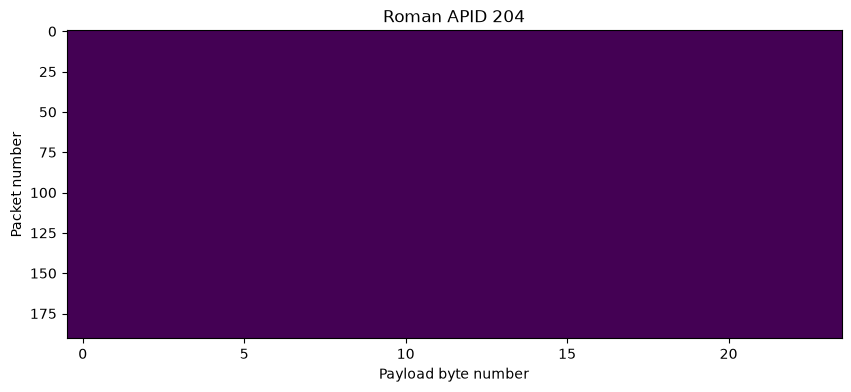

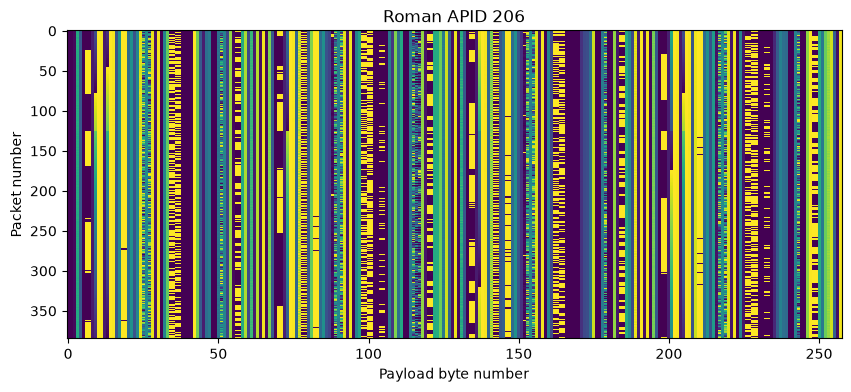

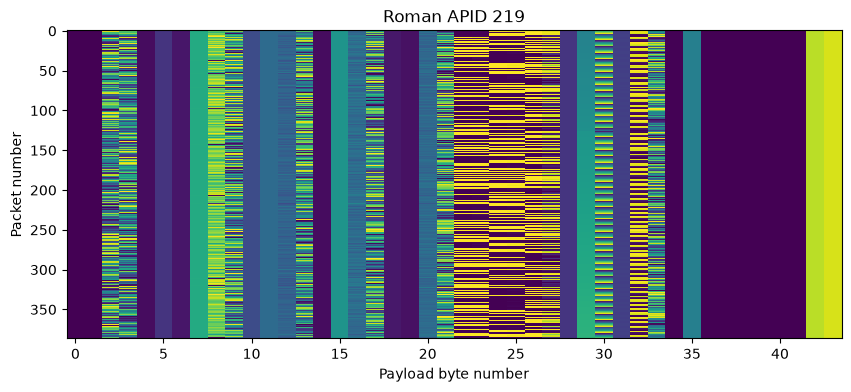

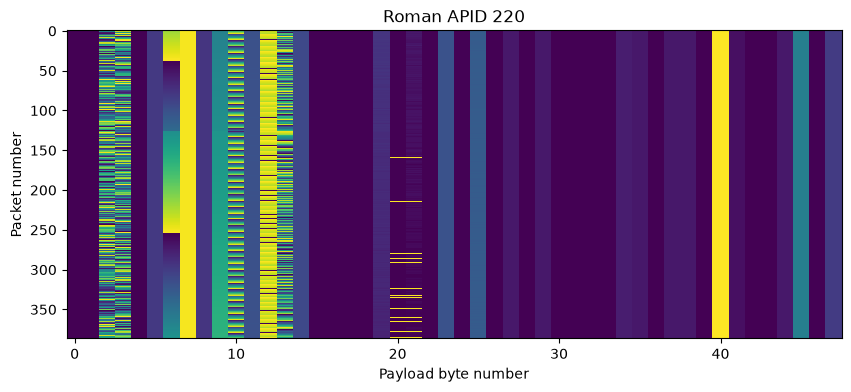

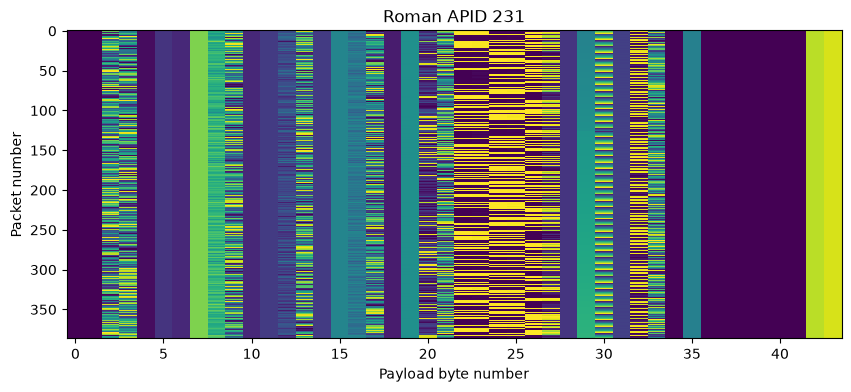

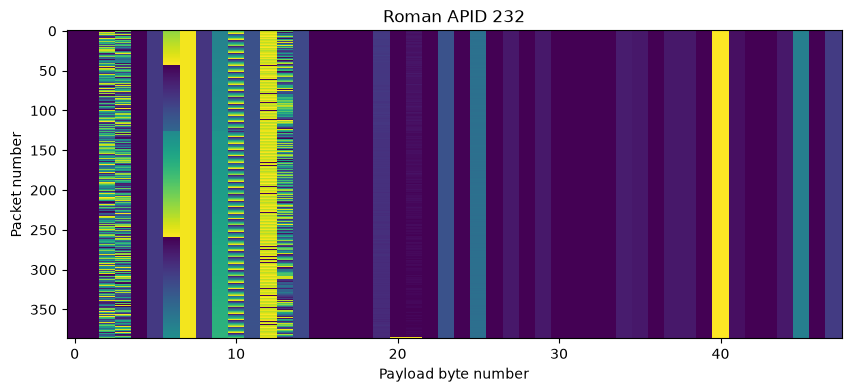

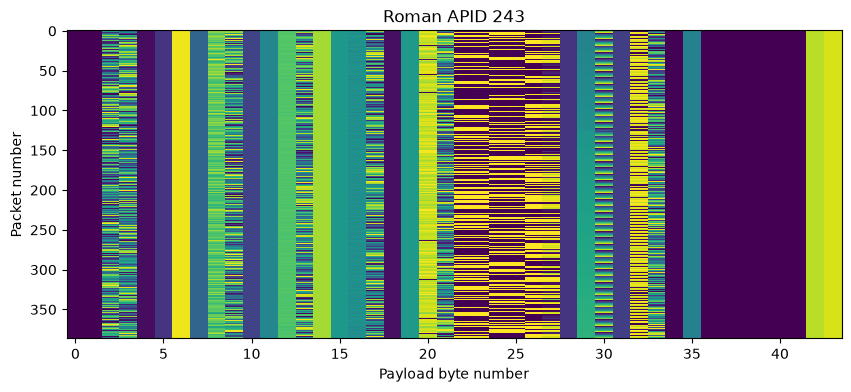

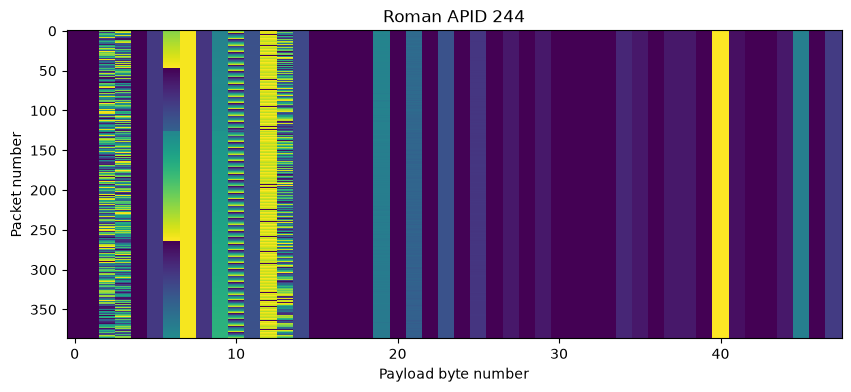

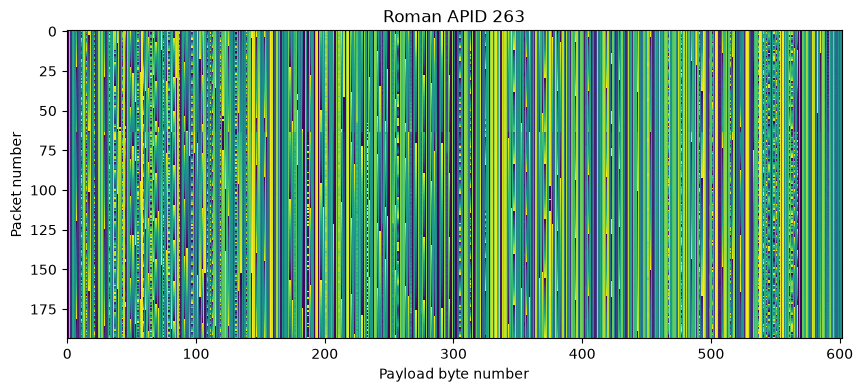

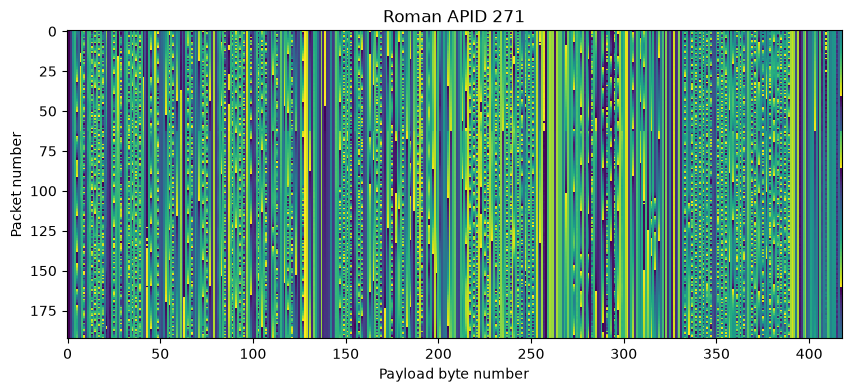

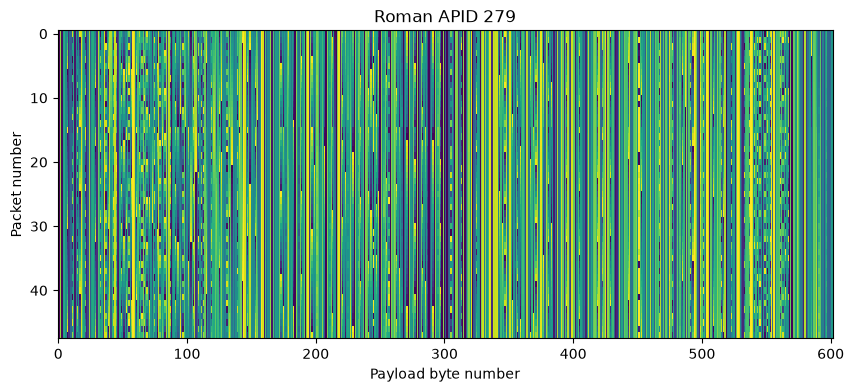

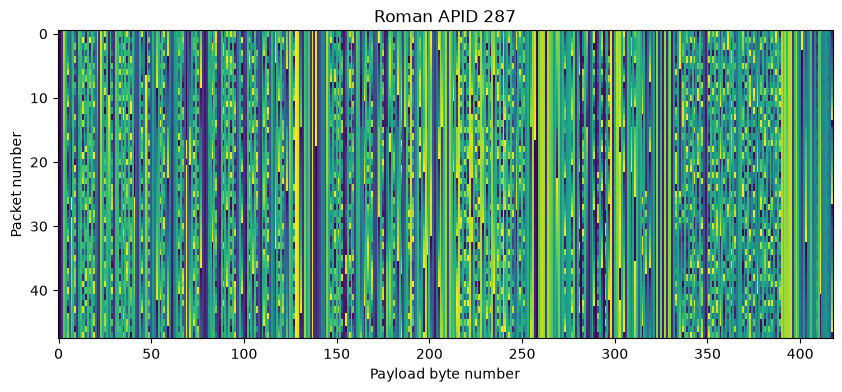

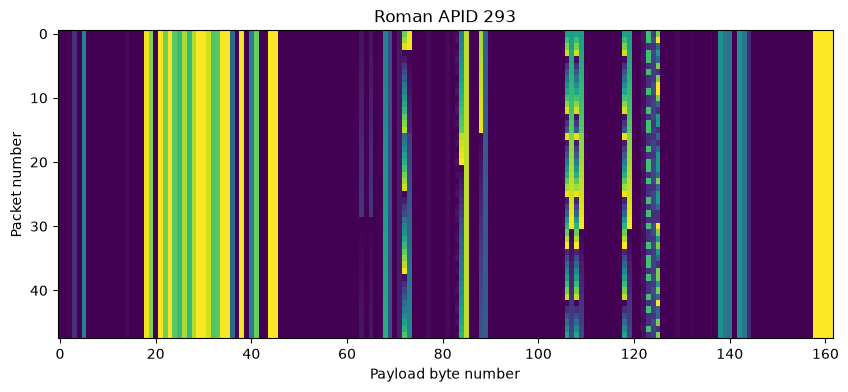

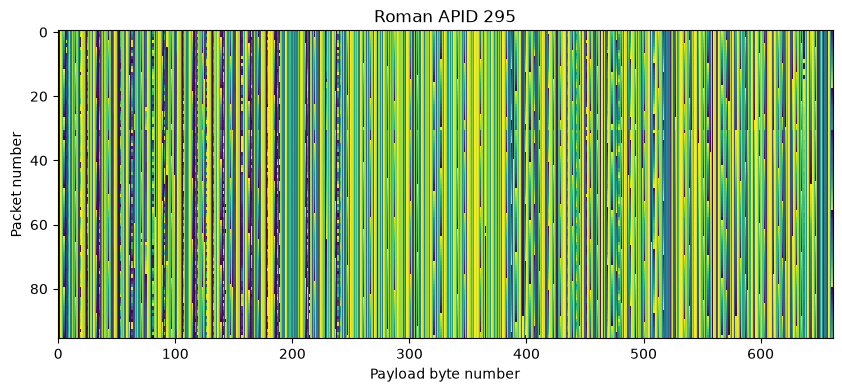

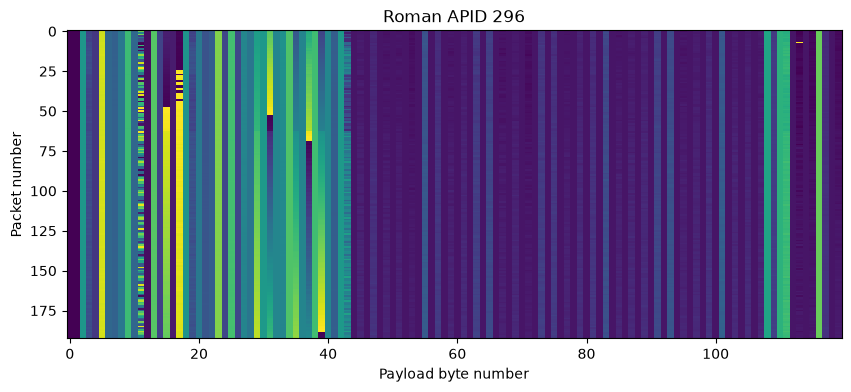

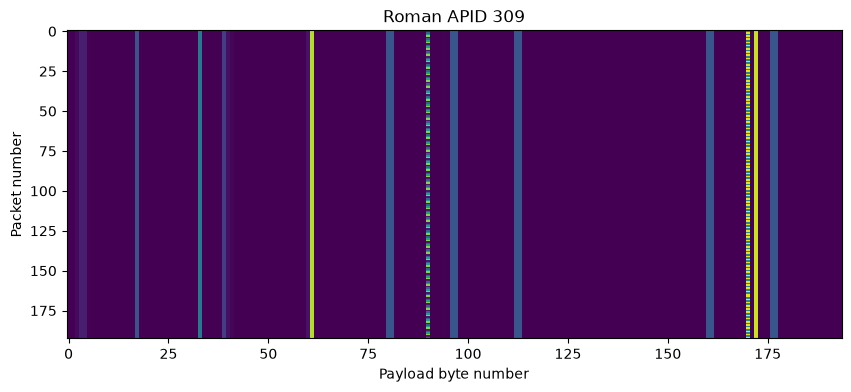

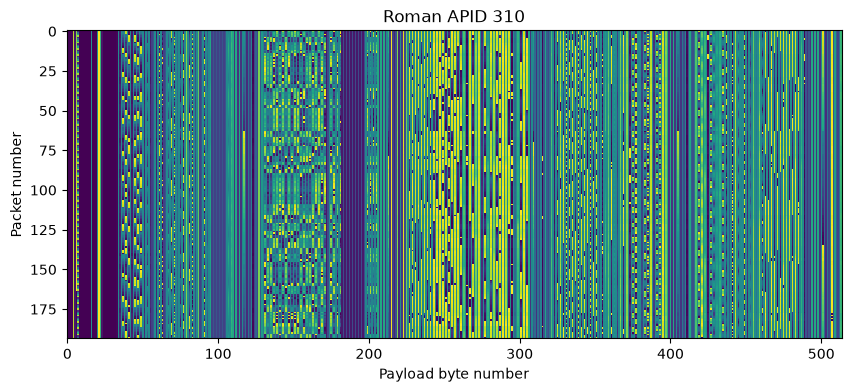

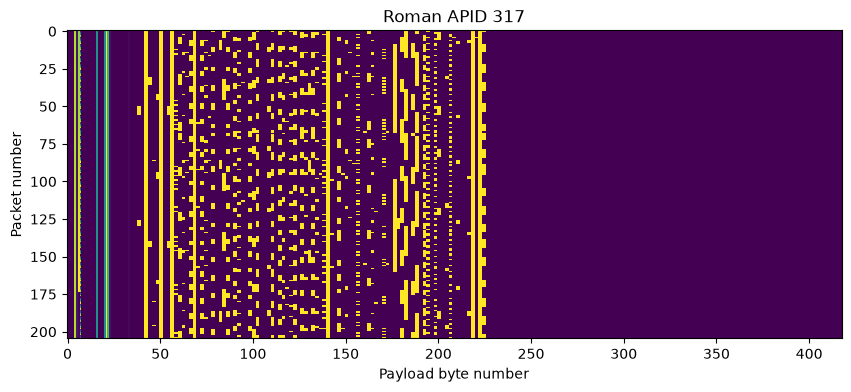

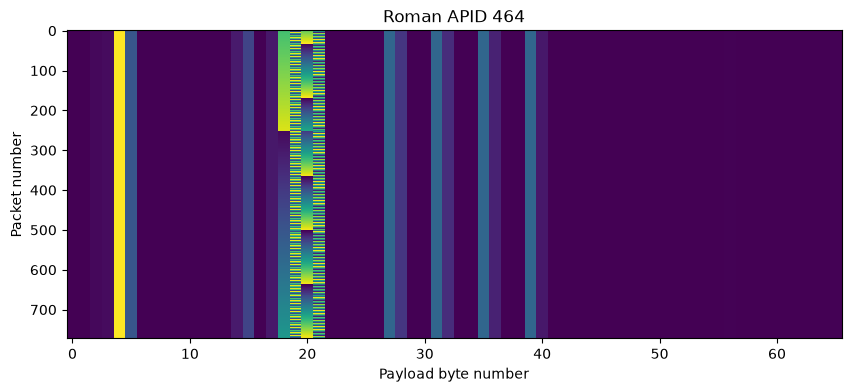

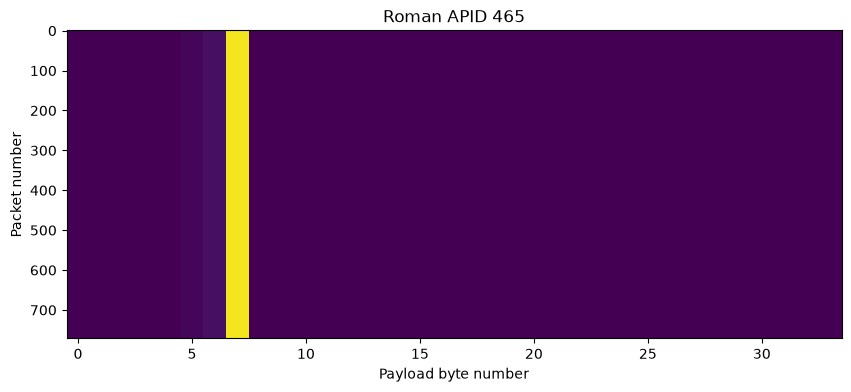

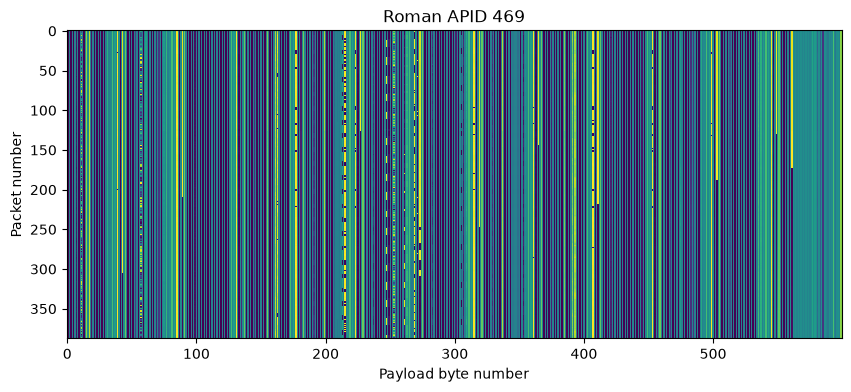

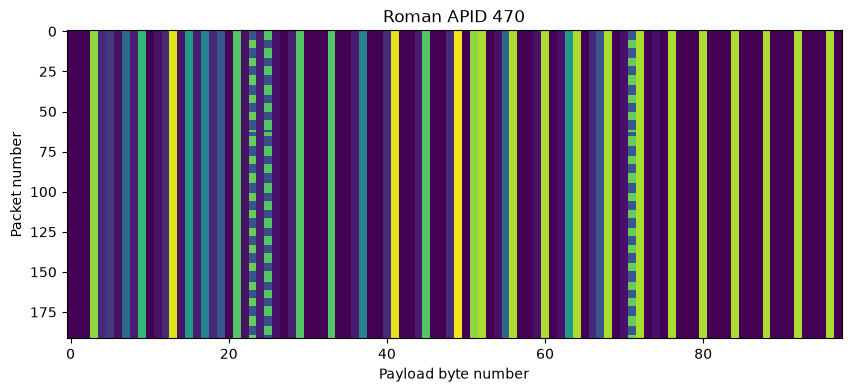

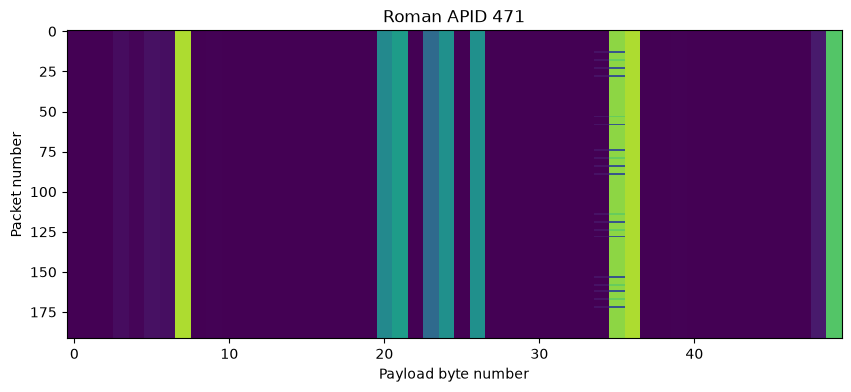

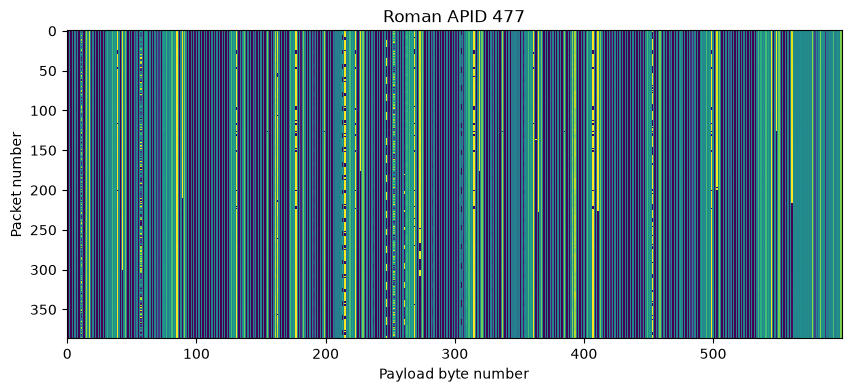

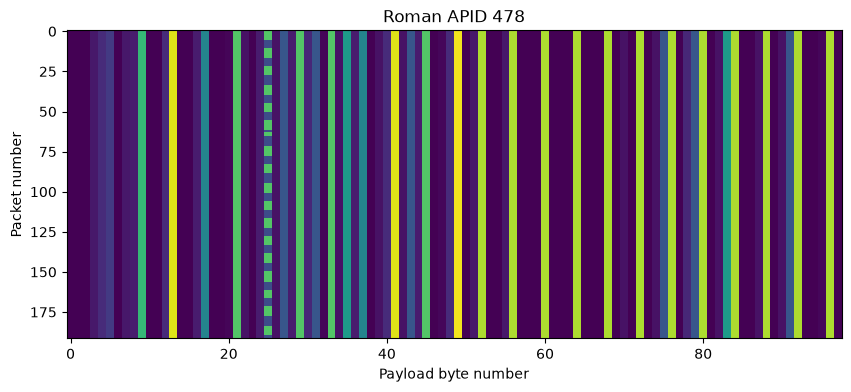

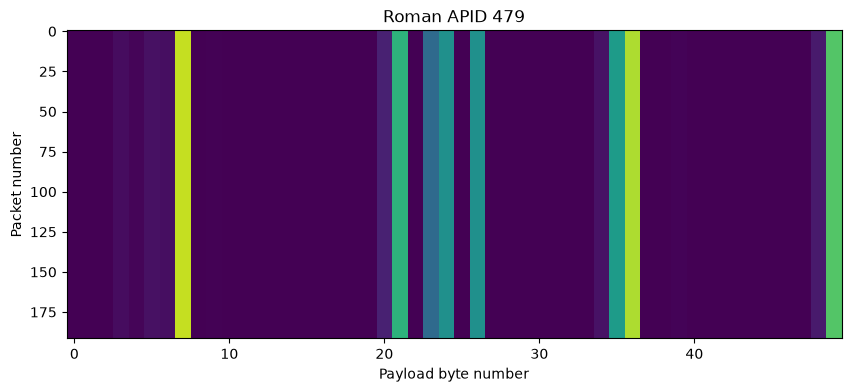

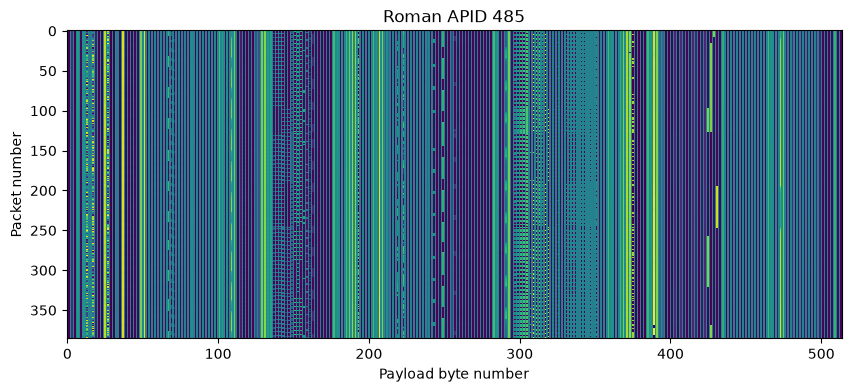

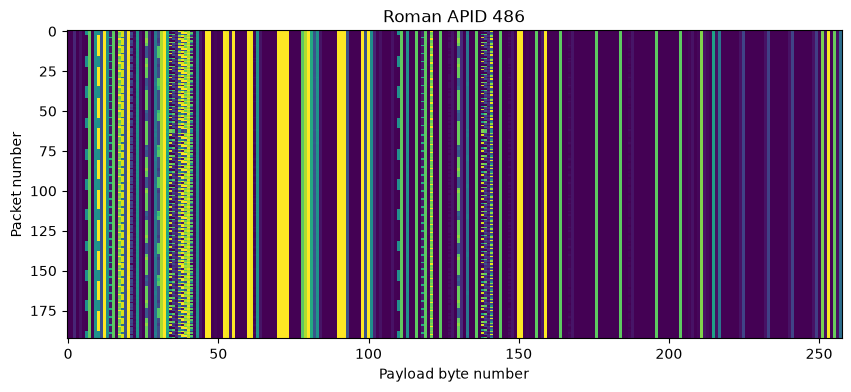

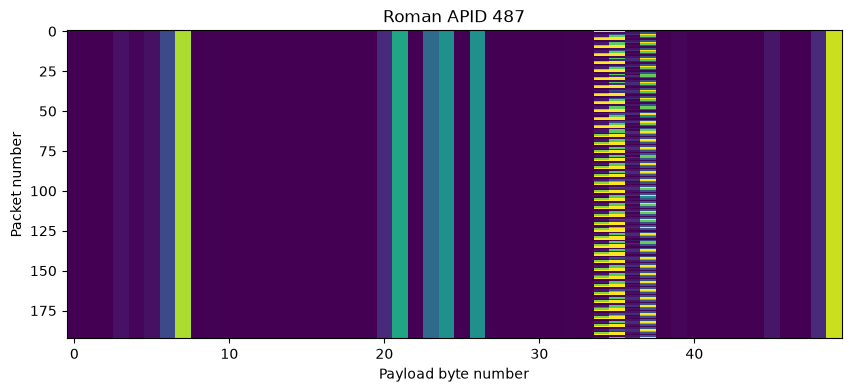

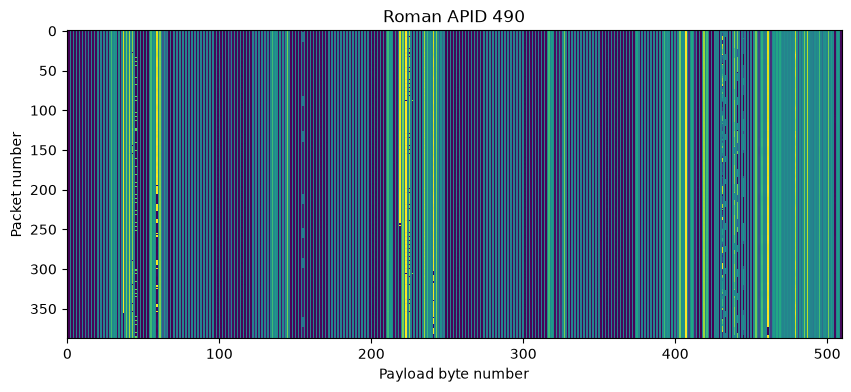

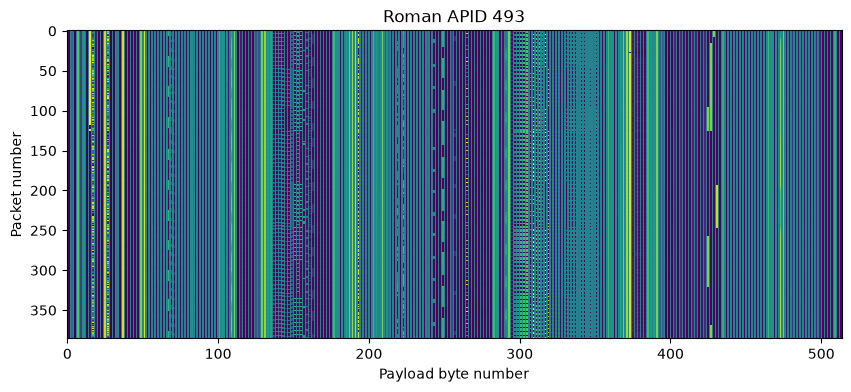

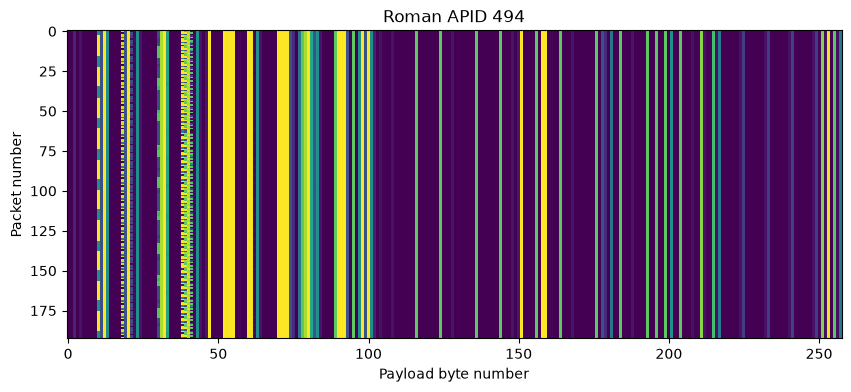

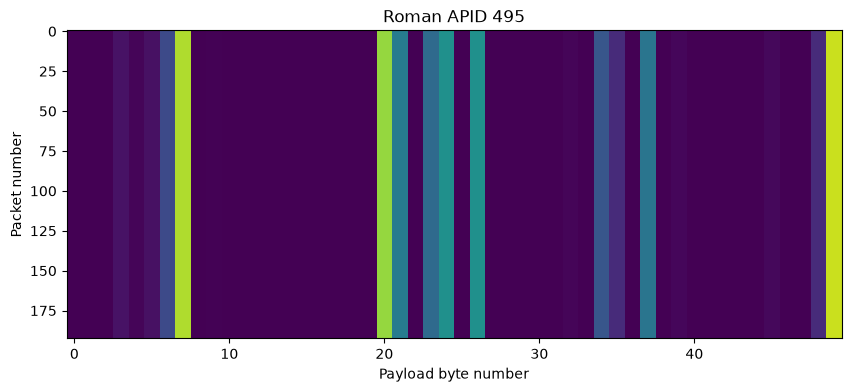

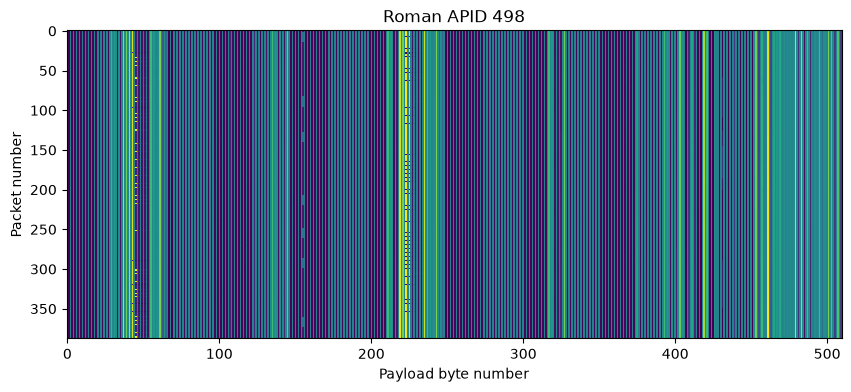

In [41]:
for apid in sorted(apids):
    plot_apid(apid)

In [42]:
payloads_by_apid(4)[0]

b"\x00\x00\x0e\x00\x02d\x00\x00\x00\x04\x00\x00&\xcd\x00\x00\x00\x00\x00DS.FILTER_TBL\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x04\x00\x04\x04\x00\x00\x00\x00\x14\x00\x02\x81'S\xd5\x1d\xa8\xaemTO.FilterTable\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00/boot/DS_LAUNCH.tbl\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00/ram/cf.config_table_262420343\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00DS.FILTER_TBL\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00

In [43]:
[p[46:].split(b'\x00')[0] for p in payloads_by_apid(8)]

[b'RTS Number 404 Started',
 b"Successfully loaded 'TO.FilterTable' from '/boot/TO_LGA_8K.tbl'",
 b'Loaded New Filter Table: /boot/TO_LGA_8K.tbl ',
 b'Set Tlm Rate Limit command: 8504',
 b'Set VC0 Real-time Rate Limit command: 8504',
 b'Processing downlink configuration for S-Comm 0',
 b'COMM 0 COMMAND VALID: 19500 sps, PR=1, RS=1, Cv=1, NRZM=0 ',
 b'Uplink SCOMMA-XPNDRB is selected as the Active Uplink',
 b'RTS 404 Execution Completed',
 b'SComm A Transponder B receiver has carrier and bit sync lock',
 b'No-op command. Version 4.9.1.0',
 b'SComm A Transponder B receiver has carrier and bit sync lock',
 b'No-op command. Version 4.9.1.0']

In [44]:
[p[66:].split(b'\x00')[0] for p in payloads_by_apid(19)]

[b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',
 b'/boot/TO_LGA_8K.tbl',


In [45]:
[p[34:].split(b'\x00')[0] for p in payloads_by_apid(22)]

[b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
 b'/boot/DS_LAUNCH.tbl',
